# 🧮 6 Gs calculs for chemical exergy

## Derive the (Standard Reference Species) SRS Chemical Exergy (B_ch)
✖️ Non-available standard (°) reference species (i) exergies (B_i^°) data

In [4]:
### we at least must used the b_chk of the reference environment species:

# --- Helper Function: Parse Chemical Formula ---
def parse_formula(formula: str, standard_state_equivalencies: Dict[str, str]) -> Dict[str, float]:
    """
    Parse a chemical formula into a dictionary of standard state species and counts.
    """
    # Handle (OH)4
    formula = formula.replace("(OH)4", "O4 H4")
    formula = formula.replace("(", "").replace(")", "")
    elements = re.findall("([A-Z][a-z]*)(\d*)", formula)
    counts = {}
    for (element, count) in elements:
        if count == "":
            count = 1
        else:
            count = int(count)
        counts[element] = counts.get(element, 0) + count
    
    # Adjust for standard states
    new_counts = {}
    for element, count in counts.items():
        if element in standard_state_equivalencies:
            std = standard_state_equivalencies[element]
            if std == "O2" and element == "O":
                new_counts[std] = new_counts.get(std, 0) + count / 2.0
            elif std == "H2" and element == "H":
                new_counts[std] = new_counts.get(std, 0) + count / 2.0
            else:
                new_counts[std] = new_counts.get(std, 0) + count
        else:
            new_counts[element] = new_counts.get(element, 0) + count
    return new_counts

def compute_b_chi_sequential(
    chem_exergy_k,
    DeltafrG_std,
    standard_state_equivalencies,
    b_chk_init,
    env_species_order
):
    """
    Strict thermodynamic back-calculation:

    b_chk = ΔGf + Σ(n_i * b_chi_i)

    RULES:
    - ONLY O2 is known initially
    - Si, H are solved (not given)
    - Al is solved last via aluminosilicates
    """

    # ------------------------------------------------------------
    # INITIAL STATE: ONLY O2 IS KNOWN
    # ------------------------------------------------------------
    b_chi = {
        "O2": b_chk_init["O2"]
    }

    def parse(species):
        return parse_formula(species, standard_state_equivalencies)

    def solve(species):
        if species not in chem_exergy_k or species not in DeltafrG_std:
            return False

        stoich = parse(species)

        known_sum = 0.0
        unknown = None

        for el, coef in stoich.items():
            if el in b_chi:
                known_sum += coef * b_chi[el]
            else:
                if unknown is None:
                    unknown = (el, coef)
                else:
                    return False  # too many unknowns

        if unknown is None:
            return False

        el, coef = unknown

        b_chi[el] = (
            chem_exergy_k[species]
            - DeltafrG_std[species]
            - known_sum
        ) / coef

        return True

    # ------------------------------------------------------------
    # STEP 1 — O2 already known
    # ------------------------------------------------------------

    # ------------------------------------------------------------
    # STEP 2 — derive Si and H FIRST (must be causal)
    # ------------------------------------------------------------
    primary_species = ["SiO2", "H2O"]

    for sp in primary_species:
        solve(sp)

    # ------------------------------------------------------------
    # STEP 3 — iterate full propagation for Al system
    # ------------------------------------------------------------
    for _ in range(5):
        for sp in env_species_order:
            solve(sp)

    return b_chi

b_chi_FS_demeester = compute_b_chi_sequential(
    chem_exergy_k=demeester_chem_exergy_k,
    DeltafrG_std=DeltafrG_std_FS,
    standard_state_equivalencies=standard_state_equivalencies,
    b_chk_init=demeester_chem_exergy_i,   # ONLY O2 is actually used
    env_species_order=[
        "SiO2",
        "H2O",
        "Al2Si2O5(OH)4"
    ]
)

# Compute b_chi for FS using each exergy method's b_chk
b_chi_FS_szargut = compute_b_chi_sequential(
    chem_exergy_k=szargut_chem_exergy_k, 
    DeltafrG_std=DeltafrG_std_FS, 
    standard_state_equivalencies=standard_state_equivalencies, 
    b_chk_init=szargut_chem_exergy_i,
    env_species_order=[
        "SiO2",
        "Al2SiO5"
    ]
)

b_chi_FS_HSC_Al2SiO5 = compute_b_chi_sequential(
    chem_exergy_k=HSC_chem_exergy_k, 
    DeltafrG_std=DeltafrG_std_FS, 
    standard_state_equivalencies=standard_state_equivalencies, 
    b_chk_init=HSC_chem_exergy_i,
    env_species_order=[
        "SiO2",
        "Al2SiO5"
    ]
)

b_chi_FS_HSC_Al2Si2O5_OH_4 = compute_b_chi_sequential(
    chem_exergy_k=HSC_chem_exergy_k, 
    DeltafrG_std=DeltafrG_std_FS, 
    standard_state_equivalencies=standard_state_equivalencies, 
    b_chk_init=HSC_chem_exergy_i,
    env_species_order=[
        "SiO2",
        "H2O",
        "Al2Si2O5(OH)4"
    ]
)

# print("b_chi from Szargut method using FS DeltafrG_std:")
# print(b_chi_FS_szargut)
# print("\nb_chi from De Meester method using FS DeltafrG_std:")
# print(b_chi_FS_demeester)   
# print("\nb_chi from HSC method using FS DeltafrG_std and Al2SiO5 as reference environment species:")
# print(b_chi_FS_HSC_Al2SiO5)
# print("\nb_chi from HSC method using FS DeltafrG_std and Al2Si2O5(OH)4 as reference environment species:")
# print(b_chi_FS_HSC_Al2Si2O5_OH_4)

Table X: Comparison of b_chi values for different methods and reference species
                    Method  b_O2     b_Si       b_Al    b_H2
         Szargut (Al2SiO5)  3.97 853.7881 1081.85735     NaN
De Meester (Al2Si2O5(OH)4)  3.97 853.7181  798.61230 244.695
             HSC (Al2SiO5)  3.92 855.0281 1096.67985     NaN
       HSC (Al2Si2O5(OH)4)  3.92 855.0281  794.54480 236.170


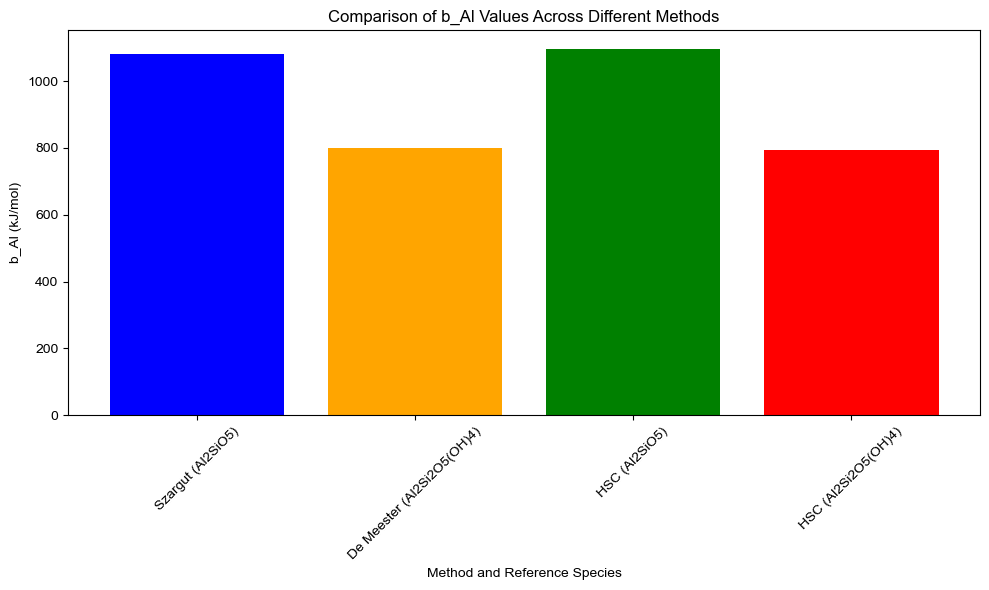

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract the results into a DataFrame for Table X
results = {
    "Method": [
        "Szargut (Al2SiO5)",
        "De Meester (Al2Si2O5(OH)4)",
        "HSC (Al2SiO5)",
        "HSC (Al2Si2O5(OH)4)"
    ],
    "b_O2": [
        b_chi_FS_szargut["O2"],
        b_chi_FS_demeester["O2"],
        b_chi_FS_HSC_Al2SiO5["O2"],
        b_chi_FS_HSC_Al2Si2O5_OH_4["O2"]
    ],
    "b_Si": [
        b_chi_FS_szargut["Si"],
        b_chi_FS_demeester["Si"],
        b_chi_FS_HSC_Al2SiO5["Si"],
        b_chi_FS_HSC_Al2Si2O5_OH_4["Si"]
    ],
    "b_Al": [
        b_chi_FS_szargut["Al"],
        b_chi_FS_demeester["Al"],
        b_chi_FS_HSC_Al2SiO5["Al"],
        b_chi_FS_HSC_Al2Si2O5_OH_4["Al"]
    ],
    "b_H2": [
        None,  # Szargut does not include H2
        b_chi_FS_demeester["H2"],
        None,  # HSC (Al2SiO5) does not include H2
        b_chi_FS_HSC_Al2Si2O5_OH_4["H2"]
    ]
}

df_results = pd.DataFrame(results)
print("Table X: Comparison of b_chi values for different methods and reference species")
print(df_results.to_string(index=False))

# Plotting the results for b_Al
plt.figure(figsize=(10, 6))
methods = ["Szargut (Al2SiO5)", "De Meester (Al2Si2O5(OH)4)", "HSC (Al2SiO5)", "HSC (Al2Si2O5(OH)4)"]
b_Al_values = [
    b_chi_FS_szargut["Al"],
    b_chi_FS_demeester["Al"],
    b_chi_FS_HSC_Al2SiO5["Al"],
    b_chi_FS_HSC_Al2Si2O5_OH_4["Al"]
]

plt.bar(methods, b_Al_values, color=['blue', 'orange', 'green', 'red'])
plt.xlabel("Method and Reference Species")
plt.ylabel("b_Al (kJ/mol)")
plt.title("Comparison of b_Al Values Across Different Methods")
plt.xticks(rotation=45)
plt.tight_layout()
# plt.show()

## Compute the 6Gs
☑️ From vailable standard (°) reference species (i) exergies (B_i^°) data

In [6]:
# --- Function: Compute G° for Elements and Compounds ---
def compute_G_std(
    species: str,
    DeltafrG_std: Dict[str, float],
    S_std: Dict[str, float],
    H_std: Dict[str, float],
    G_std: Dict[str, float],
    reference_elements: List[str],
    standard_state_equivalencies: Dict[str, str],
    Tenv: float
) -> Optional[float]:
    """
    Compute G° (kJ/mol) for a species at given temperature.
    """
    if species in G_std:
        return G_std[species]
    
    # Check if species is an element (in standard state)
    if species in reference_elements:
        if species in S_std:
            return -Tenv * S_std[species] / 1000  # Convert J to kJ
        else:
            return None
    
    # For compounds, use ΔG°f + sum of elements' G°
    if species in DeltafrG_std:
        elements = parse_formula(species, standard_state_equivalencies)
        G_elements = 0
        for element, count in elements.items():
            G_element = compute_G_std(
                element, DeltafrG_std, S_std, H_std, G_std, 
                reference_elements, standard_state_equivalencies, Tenv
            )
            if G_element is None:
                return None
            G_elements += count * G_element
        return DeltafrG_std[species] + G_elements
    
    # Try from H° and S° if available
    if species in S_std and species in H_std:
        return H_std[species] - Tenv * S_std[species] / 1000
    
    return None

# --- Function: Compute G for Reference State sum_i (elements) ---
def compute_std_G_sumi_in_j(
    reaction_formation: Dict[str, float],
    S_std: Dict[str, float],
    Tenv: float
) -> float:
    """
    Compute G(∑i, °) = Σ (stoich_coef * G°_element)
    """
    G_sum_i = 0.0
    for species, coef in reaction_formation.items():
        if coef < 0:  # Reactants (elements)
            if species in S_std:
                G_element = -Tenv * S_std[species] / 1000
                G_sum_i += abs(coef) * G_element
            else:
                raise ValueError(f"Missing S° for element {species}")
    return G_sum_i

# --- Function: Compute G for Reference State sum_k (environmental species) ---
def compute_std_G_sumk_in_j(
    DeltafrG_std: Dict[str, float],
    S_std: Dict[str, float],
    H_std: Dict[str, float],
    G_std: Dict[str, float],
    reference_elements: List[str],
    standard_state_equivalencies: Dict[str, str],
    Tenv: float,
    reaction_formation_j_from_k: Dict[str, float],
    resource: str
) -> float:
    """
    Compute G(∑k, °) = Σ (-coef_k * G°_k_species) from the reaction j = Σ coef_k * k
    """
    G_sum_k = 0.0
    for species, coef in reaction_formation_j_from_k.items():
        if species == resource:
            continue
        G_species = compute_G_std(
            species, DeltafrG_std, S_std, H_std, G_std,
            reference_elements, standard_state_equivalencies, Tenv
        )
        if G_species is None:
            raise ValueError(f"Cannot compute G° for {species}")
        G_sum_k += -coef * G_species
    return G_sum_k

# --- Function: Compute the value of chemical exergy of the sum of environment reference species k present in the resource j
def compute_sumk_in_j(
    chem_exergy_k: Dict[str, float],
    reaction_formation_jfrom_k: Dict[str, float]
) -> float:
    """
    Compute Szargut(∑k, env) from chemical exergies of environmental species
    Based on reaction: j = Al2O3 = Al2SiO5 - SiO2 for Szargut reference environment species
        or j = Al2O3 = Al2Si2O5(OH)4 - 2*SiO2 - 2*H2O for De Meester reference environment species
    """
    # For reaction: Al2O3 -> Al2SiO5 - SiO2
    # B_sumk_in_j = Σ (coef_k * exergy_k) with signs opposite to formation
    if reaction_formation_jfrom_k == reaction_formation_jfromks_sc_szargut:
        szargut_value = 0.0
        for species, coef in reaction_formation_jfrom_k.items():
            if species in chem_exergy_k:
                if species == "Al2O3":
                    continue  # Skip the resource species
                szargut_value += -coef * chem_exergy_k[species]
        return szargut_value
    if reaction_formation_jfrom_k == reaction_formation_jfromks_sc_demeester:
        demeester_value = 0.0
        for species, coef in reaction_formation_jfrom_k.items():
            if species in chem_exergy_k:
                if species == "Al2O3":
                    continue  # Skip the resource species
                demeester_value += -coef * chem_exergy_k[species]
        return demeester_value

# --- Function: Compute the value of chemical exergy of the sum of standard reference species i present in the resource j
def compute_sumi_in_j(
    chem_exergy_i: Dict[str, float],
    reaction_formation_jfrom_i: Dict[str, float]
) -> float:
    """
    Compute Szargut(∑\nν_i * B_ch,i) from chemical exergies of reference elements
    Based on reaction: j = Al2O3 = 2Al + 1.5O2
    """
    # For reaction: Al2O3 -> 2Al + 1.5O2
    # B_sumi_in_j = Σ (coef_i * exergy_i) with signs opposite to formation
    szargut_value = 0.0
    for species, coef in reaction_formation_jfrom_i.items():
        if species in chem_exergy_i:
            if species == "Al2O3":
                continue  # Skip the resource species
            szargut_value += -coef * chem_exergy_i[species]
    return szargut_value

# --- Main Function: Compute All 6 G Values ---
def compute_all_G_values(
    # Thermodynamic data
    DeltafrG_std: Dict[str, float],
    S_std: Dict[str, float],
    H_std: Dict[str, float],
    G_std: Dict[str, float],
    
    # Chemical systems
    resource: str,
    reference_elements_i: List[str],
    reference_species_k: List[str],
    
    # Reactions
    reaction_formation_j_from_i: Mapping[str, float],
    reaction_formation_j_from_k: Mapping[str, float],
    
    # Szargut data
    chem_exergy_k: Dict[str, float],
    chem_exergy_i: Dict[str, float],  # Chemical exergies of elements for Szargut(∑ν_i * B_ch,i)
    
    # Environment
    Tenv: float,
    
    # Helpers
    standard_state_equivalencies: Dict[str, str]
) -> Dict[str, float]:
    """
    Compute all 6 G values and related quantities.
    Returns dictionary with all computed values.
    """
    
    results = {}
    
    # Step 1: Compute G(∑i, °)
    results["G_std_sumi_in_j"] = compute_std_G_sumi_in_j(
        reaction_formation_j_from_i, S_std, Tenv
    )
    
    # Step 2: Compute G(j, °) for resource
    G_std_resource = compute_G_std(
        resource, DeltafrG_std, S_std, H_std, G_std,
        reference_elements_i, standard_state_equivalencies, Tenv
    )
    if G_std_resource is None:
        raise ValueError(f"Cannot compute G° for {resource}")
    results["G_std_j"] = G_std_resource
    
    # Step 3: Compute G(∑k, °)
    results["G_std_sumk_in_j"] = compute_std_G_sumk_in_j(
        DeltafrG_std, S_std, H_std, G_std,
        reference_elements_i, standard_state_equivalencies, Tenv,
        reaction_formation_j_from_k, resource
    )
    
    # Step 4: Compute Szargut exergies for ∑k and ∑i
    results["B_sumk_in_j"] = compute_sumk_in_j(
        chem_exergy_k, reaction_formation_j_from_k
    )
    results["B_sumi_in_j"] = compute_sumi_in_j(
        chem_exergy_i, reaction_formation_j_from_i
    )

    
    # Step 5: Compute G(∑k, env) from relation:
    # G(∑k, °) - G(∑k, env) = B_sumk_in_j(∑ν_k * B_ch,k)
    results["G_env_sumk_in_j"] = results["G_std_sumk_in_j"] - results["B_sumk_in_j"]
    
    # Step 6.1: Compute ΔG° for reaction j ← k
    DeltaG_std_jk = results["G_std_j"] - results["G_std_sumk_in_j"]
    # Step 6.2: Compute ΔG° for reaction j ← i
    DeltaG_std_ji = results["G_std_j"] - results["G_std_sumi_in_j"]
    # Step 6.3: Compute ΔG° for reaction k ← i
    DeltaG_std_ki = results["G_std_sumk_in_j"] - results["G_std_sumi_in_j"]
    
    # Step 7: Compute G(j, env) assuming ΔG^env = ΔG° (only thermomechanical contributions in chemical exergy)
    results["G_env_j"] = DeltaG_std_jk + results["G_env_sumk_in_j"]
    
    # Step 8: Compute G(∑i, env) from B_sumi_in_j(∑ν_i * B_ch,i)
    # DeltaG_std_ji = G(j, °) - G(∑i, °) = G(j, env) - G(∑i, env) => G(∑i, env) = G(j, env) - DeltaG_std_ji
    results["G_env_sumi_in_j"] = results["G_env_j"] - DeltaG_std_ji # can be determined from other ways:
    # results["G_env_sumi_in_j"] = results["G_env_sumk_in_j"] - DeltaG_std_ki # for instance
    
    # Step 9: Compute derived quantities for verification
    results["B_j"] = results["G_std_j"] - results["G_env_sumk_in_j"] # based on Edward and Simpson definition of chemical exergy 📖 https://doi.org/10.1016/j.energy.2011.01.025
    results["DeltaG_std_jk"] = DeltaG_std_jk
    results["DeltaG_env_jk"] = results["G_env_j"] - results["G_env_sumk_in_j"]
    results["DeltaG_std_ji"] = results["G_std_j"] - results["G_std_sumi_in_j"]
    results["DeltaG_env_ji"] = results["G_env_j"] - results["G_env_sumi_in_j"]
    
    return results

# --- Function: Create Results DataFrame ---
def create_results_dataframe(results_dict: Dict[str, float]) -> pd.DataFrame:
    """
    Create a formatted DataFrame from results dictionary.
    """
    # Define the 6 main G values
    main_G_values = {
        "G(∑k, env)": results_dict["G_env_sumk_in_j"],
        "G(j, env)": results_dict["G_env_j"],
        "G(∑k, °)": results_dict["G_std_sumk_in_j"],
        "G(j, °)": results_dict["G_std_j"],
        "G(∑i, env)": results_dict["G_env_sumi_in_j"],
        "G(∑i, °)": results_dict["G_std_sumi_in_j"]
    }
    
    # Create DataFrame for main results
    df_main = pd.DataFrame([
        {"Parameter": k, "Value (kJ/mol)": v, "Type": "Main G Value"}
        for k, v in main_G_values.items()
    ])
    
    # Create DataFrame for derived quantities
    derived_quantities = {
        "B_sumk_in_j(∑ν_k * B_ch,k)": results_dict["B_sumk_in_j"],
        "B_sumi_in_j(∑ν_i * B_ch,i)": results_dict["B_sumi_in_j"],
        "B_j (Chemical Exergy of the resource)": results_dict["B_j"],
        "ΔG°(j ← k)": results_dict["DeltaG_std_jk"],
        "ΔG^env(j ← k)": results_dict["DeltaG_env_jk"],
        "ΔG°(j ← i)": results_dict["DeltaG_std_ji"],
        "ΔG^env(j ← i)": results_dict["DeltaG_env_ji"]
    }
    
    df_derived = pd.DataFrame([
        {"Parameter": k, "Value (kJ/mol)": v, "Type": "Derived Quantity"}
        for k, v in derived_quantities.items()
    ])
    
    # Combine both DataFrames
    df_results = pd.concat([df_main, df_derived], ignore_index=True)
    
    return df_results

# 📊 results 

## SRS B_ch

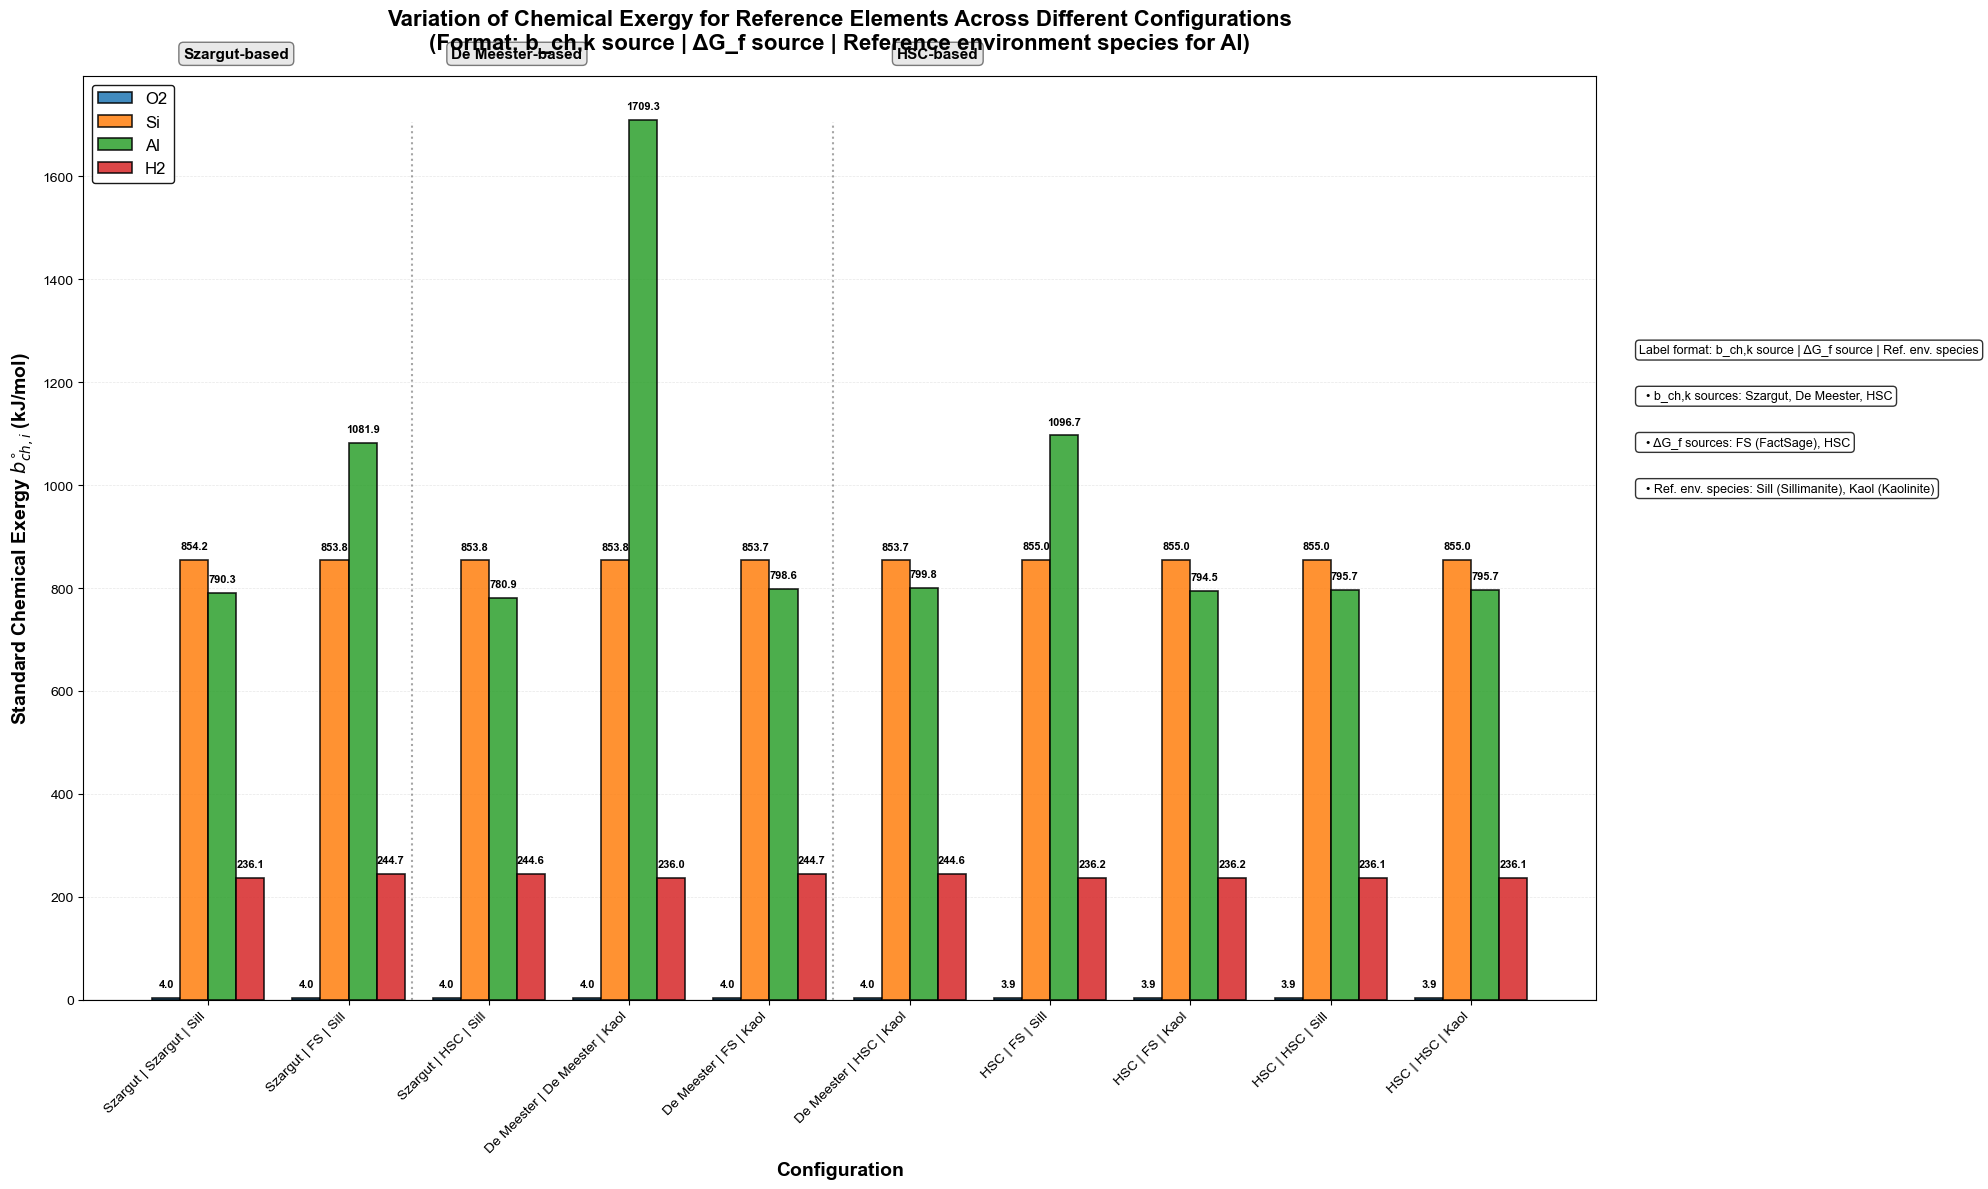

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Define all configurations with detailed metadata
configurations = [
    {
        "name": "Szargut + Szargut",
        "chem_exergy_source": "Szargut",
        "DeltafrG_source": "Szargut",
        "env_species_Al": "Sillimanite",
        "short_label": "Szargut | Szargut | Sill",
        "chem_exergy_k": szargut_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_szargut_brgm,
        "b_chk_init": szargut_chem_exergy_i,
        "env_species_order": ["SiO2", "Al2SiO5"],
    },
    {
        "name": "Szargut + FactSage",
        "chem_exergy_source": "Szargut",
        "DeltafrG_source": "FactSage",
        "env_species_Al": "Sillimanite",
        "short_label": "Szargut | FS | Sill",
        "chem_exergy_k": szargut_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_FS,
        "b_chk_init": szargut_chem_exergy_i,
        "env_species_order": ["SiO2", "Al2SiO5"],
    },
    {
        "name": "Szargut + HSC",
        "chem_exergy_source": "Szargut",
        "DeltafrG_source": "HSC",
        "env_species_Al": "Sillimanite",
        "short_label": "Szargut | HSC | Sill",
        "chem_exergy_k": szargut_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_HSC,
        "b_chk_init": szargut_chem_exergy_i,
        "env_species_order": ["SiO2", "Al2SiO5"],
    },
    {
        "name": "De Meester + De Meester",
        "chem_exergy_source": "De Meester",
        "DeltafrG_source": "De Meester",
        "env_species_Al": "Kaolinite",
        "short_label": "De Meester | De Meester | Kaol",
        "chem_exergy_k": demeester_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_demeester_brgm,
        "b_chk_init": demeester_chem_exergy_i,
        "env_species_order": ["SiO2", "H2O", "Al2Si2O5(OH)4"],
    },
    {
        "name": "De Meester + FactSage",
        "chem_exergy_source": "De Meester",
        "DeltafrG_source": "FactSage",
        "env_species_Al": "Kaolinite",
        "short_label": "De Meester | FS | Kaol",
        "chem_exergy_k": demeester_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_FS,
        "b_chk_init": demeester_chem_exergy_i,
        "env_species_order": ["SiO2", "H2O", "Al2Si2O5(OH)4"],
    },
    {
        "name": "De Meester + HSC",
        "chem_exergy_source": "De Meester",
        "DeltafrG_source": "HSC",
        "env_species_Al": "Kaolinite",
        "short_label": "De Meester | HSC | Kaol",
        "chem_exergy_k": demeester_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_HSC,
        "b_chk_init": demeester_chem_exergy_i,
        "env_species_order": ["SiO2", "H2O", "Al2Si2O5(OH)4"],
    },
    {
        "name": "HSC + FactSage (Sillimanite)",
        "chem_exergy_source": "HSC",
        "DeltafrG_source": "FactSage",
        "env_species_Al": "Sillimanite",
        "short_label": "HSC | FS | Sill",
        "chem_exergy_k": HSC_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_FS,
        "b_chk_init": HSC_chem_exergy_i,
        "env_species_order": ["SiO2", "Al2SiO5"],
    },
    {
        "name": "HSC + FactSage (Kaolinite)",
        "chem_exergy_source": "HSC",
        "DeltafrG_source": "FactSage",
        "env_species_Al": "Kaolinite",
        "short_label": "HSC | FS | Kaol",
        "chem_exergy_k": HSC_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_FS,
        "b_chk_init": HSC_chem_exergy_i,
        "env_species_order": ["SiO2", "H2O", "Al2Si2O5(OH)4"],
    },
    {
        "name": "HSC + HSC (Sillimanite)",
        "chem_exergy_source": "HSC",
        "DeltafrG_source": "HSC",
        "env_species_Al": "Sillimanite",
        "short_label": "HSC | HSC | Sill",
        "chem_exergy_k": HSC_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_HSC,
        "b_chk_init": HSC_chem_exergy_i,
        "env_species_order": ["SiO2", "Al2SiO5"],
    },
    {
        "name": "HSC + HSC (Kaolinite)",
        "chem_exergy_source": "HSC",
        "DeltafrG_source": "HSC",
        "env_species_Al": "Kaolinite",
        "short_label": "HSC | HSC | Kaol",
        "chem_exergy_k": HSC_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_HSC,
        "b_chk_init": HSC_chem_exergy_i,
        "env_species_order": ["SiO2", "H2O", "Al2Si2O5(OH)4"],
    },
]

# Compute b_chi for all configurations
results_all_configs = []
for config in configurations:
    b_chi = compute_b_chi_sequential(
        chem_exergy_k=config["chem_exergy_k"],
        DeltafrG_std=config["DeltafrG_std"],
        standard_state_equivalencies=standard_state_equivalencies,
        b_chk_init=config["b_chk_init"],
        env_species_order=config["env_species_order"],
    )
    results_all_configs.append({
        "name": config["name"],
        "short_label": config["short_label"],
        "chem_exergy_source": config["chem_exergy_source"],
        "DeltafrG_source": config["DeltafrG_source"],
        "env_species_Al": config["env_species_Al"],
        "b_chi": b_chi,
    })

# Extract b_chi values
b_chi_values = []
for result in results_all_configs:
    b_chi_values.append({
        "short_label": result["short_label"],
        "b_O2": result["b_chi"]["O2"],
        "b_Si": result["b_chi"]["Si"],
        "b_Al": result["b_chi"]["Al"],
        "b_H2": result["b_chi"].get("H2", None),
    })

df_b_chi = pd.DataFrame(b_chi_values)
df_b_chi["b_H2"] = df_b_chi["b_H2"].fillna(0)

# Create single comprehensive plot
fig, ax = plt.subplots(figsize=(20, 12))

# Set up bar positions
x = np.arange(len(df_b_chi))
width = 0.2
multiplier = 0

# Define colors for each element
colors = {
    'b_O2': '#1f77b4',  # blue
    'b_Si': '#ff7f0e',  # orange
    'b_Al': '#2ca02c',  # green
    'b_H2': '#d62728'   # red
}

# Plot bars for each element
for element, color in colors.items():
    offset = width * multiplier
    values = df_b_chi[element].values
    bars = ax.bar(x + offset, values, width, label=element.replace('b_', ''), 
                  color=color, edgecolor='black', linewidth=1.2, alpha=0.85)
    
    # Add value labels on top of bars (only for positive values)
    for bar, val in zip(bars, values):
        # Convert val to float if it's numeric, skip if it's not
        try:
            val_float = float(val)
            if val_float > 0:
                height = bar.get_height()
                ax.text(bar.get_x() + bar.get_width()/2., height + max(df_b_chi[['b_O2', 'b_Si', 'b_Al', 'b_H2']].max()) * 0.01,
                    f'{val_float:.1f}', ha='center', va='bottom', fontsize=8, rotation=0, fontweight='bold')
        except (ValueError, TypeError):
            pass  # Skip non-numeric values (like "—") 
    multiplier += 1

# Customize the plot
ax.set_xlabel('Configuration', fontsize=14, fontweight='bold')
ax.set_ylabel('Standard Chemical Exergy $b_{ch,i}^{\\circ}$ (kJ/mol)', fontsize=14, fontweight='bold')
ax.set_title('Variation of Chemical Exergy for Reference Elements Across Different Configurations\n(Format: b_ch,k source | ΔG_f source | Reference environment species for Al)', 
             fontsize=16, fontweight='bold', pad=20)

# Set x-ticks with short labels
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(df_b_chi['short_label'], rotation=45, ha='right', fontsize=10)

# Add legend
ax.legend(loc='upper left', fontsize=12, framealpha=0.9, edgecolor='black')

# Add grid
ax.grid(axis='y', linestyle='--', alpha=0.3, linewidth=0.5)
ax.set_axisbelow(True)

# Add horizontal line at y=0 if needed
ax.axhline(y=0, color='black', linestyle='-', linewidth=0.8)

# Add background shading to separate different b_ch,k sources
y_min, y_max = ax.get_ylim()
y_range = y_max - y_min

# Add annotations for grouping
bbox_props = dict(boxstyle="round,pad=0.3", facecolor="lightgray", alpha=0.5)

# Group 1: Szargut based
ax.text(0.5, y_max + y_range*0.02, 'Szargut-based', ha='center', fontsize=11, 
        fontweight='bold', bbox=bbox_props)

# Group 2: De Meester based
ax.text(2.5, y_max + y_range*0.02, 'De Meester-based', ha='center', fontsize=11, 
        fontweight='bold', bbox=bbox_props)

# Group 3: HSC based
ax.text(5.5, y_max + y_range*0.02, 'HSC-based', ha='center', fontsize=11, 
        fontweight='bold', bbox=bbox_props)

# Add separator lines between groups
ax.axvline(x=1.75, ymin=0, ymax=0.95, color='gray', linestyle=':', linewidth=1.5, alpha=0.7)
ax.axvline(x=4.75, ymin=0, ymax=0.95, color='gray', linestyle=':', linewidth=1.5, alpha=0.7)

# Add color-coded legend for the short label format
legend_text = [
    "Label format: b_ch,k source | ΔG_f source | Ref. env. species",
    "  • b_ch,k sources: Szargut, De Meester, HSC",
    "  • ΔG_f sources: FS (FactSage), HSC",
    "  • Ref. env. species: Sill (Sillimanite), Kaol (Kaolinite)"
]
text_x = x[-1] + 1.5
text_y = y_max - y_range*0.3
for i, text in enumerate(legend_text):
    ax.text(text_x, text_y - i*y_range*0.05, text, fontsize=9, 
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

# Adjust layout
plt.tight_layout()

# Save as SVG
plt.savefig('chemical_exergy_variation_all_configurations.svg', format='svg', dpi=300, bbox_inches='tight')
#  plt.savefig('chemical_exergy_variation_all_configurations.png', dpi=300, bbox_inches='tight')

plt.show()

# # Print the detailed table
# print("\n" + "="*100)
# print("TABLE: Standard chemical exergy of reference elements (b_chi) for all configurations")
# print("="*100)
# print(f"{'Configuration (b_ch,k | ΔG_f | Ref.Env.)':<40} {'b_O2 (kJ/mol)':<20} {'b_Si (kJ/mol)':<20} {'b_Al (kJ/mol)':<20} {'b_H2 (kJ/mol)':<20}")
# print("-"*100)
# for idx, row in df_b_chi.iterrows():
#     print(f"{row['short_label']:<40} {row['b_O2']:<20.2f} {row['b_Si']:<20.2f} {row['b_Al']:<20.2f} {row['b_H2']:<20.2f}")
# print("="*100)

# # Statistical analysis
# print("\n" + "="*100)
# print("STATISTICAL ANALYSIS")
# print("="*100)
# for element in ['b_O2', 'b_Si', 'b_Al', 'b_H2']:
#     values = df_b_chi[element].values
#     if np.all(values == 0):
#         continue
#     print(f"\n{element.replace('b_', '')}:")
#     print(f"  Mean: {np.mean(values):.2f} kJ/mol")
#     print(f"  Std Dev: {np.std(values):.2f} kJ/mol")
#     print(f"  Min: {np.min(values):.2f} kJ/mol")
#     print(f"  Max: {np.max(values):.2f} kJ/mol")
#     print(f"  Range: {np.max(values) - np.min(values):.2f} kJ/mol")

### SRS B_ch: 1 plot SRS

C:\Users\lfreboeuf\AppData\Local\Temp\ipykernel_6588\194433821.py:54: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\lfreboeuf\AppData\Local\Temp\ipykernel_6588\194433821.py:55: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig('chemical_exergy_all_elements.svg', format='svg', dpi=300, bbox_inches='tight')
C:\Users\lfreboeuf\AppData\Local\Temp\ipykernel_6588\194433821.py:56: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig('chemical_exergy_all_elements.png', dpi=300, bbox_inches='tight')
c:\ProgramData\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


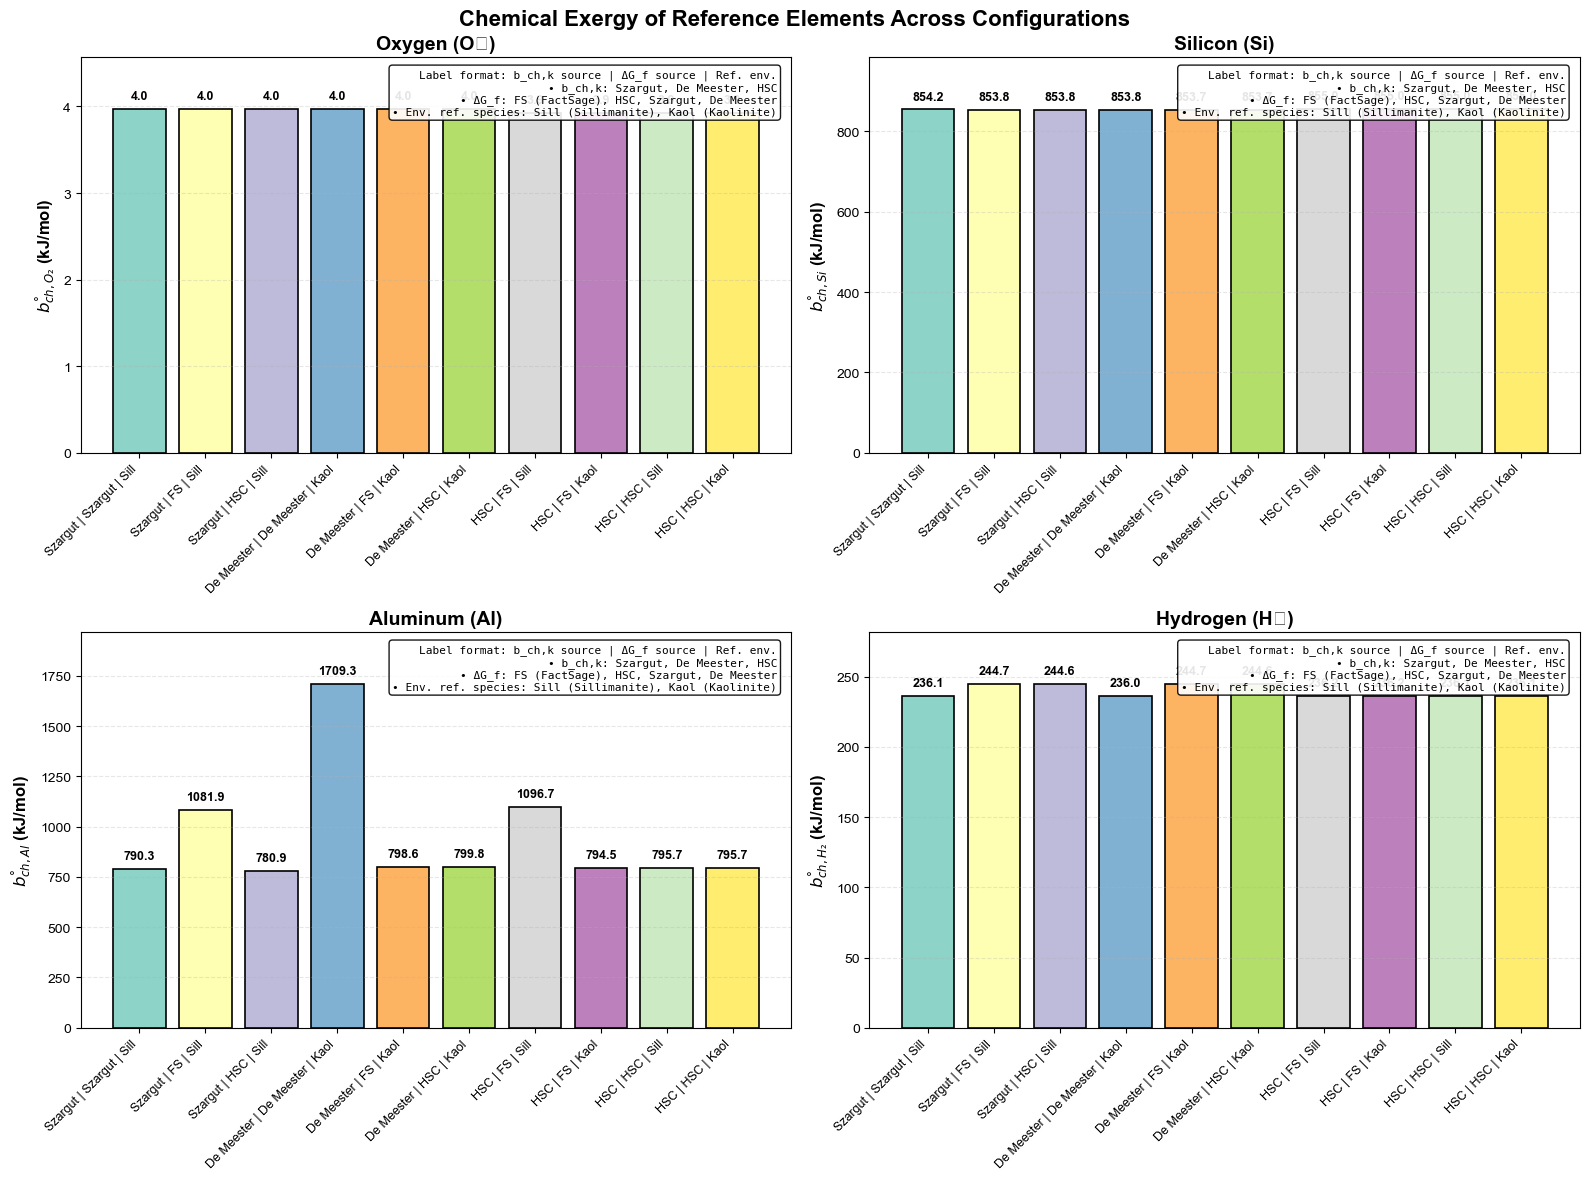


TABLE: Standard chemical exergy of reference elements (b_chi) for all configurations
Configuration (b_ch,k | ΔG_f | Ref.Env.) O₂ (kJ/mol)          Si (kJ/mol)          Al (kJ/mol)          H₂ (kJ/mol)         
----------------------------------------------------------------------------------------------------
Szargut | Szargut | Sill                 3.97                 854.17               790.34               236.09              
Szargut | FS | Sill                      3.97                 853.79               1081.86              244.69              
Szargut | HSC | Sill                     3.97                 853.75               780.88               244.65              
De Meester | De Meester | Kaol           3.97                 853.80               1709.29              236.00              
De Meester | FS | Kaol                   3.97                 853.72               798.61               244.69              
De Meester | HSC | Kaol                  3.97                 8

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# After computing results_all_configs and creating df_b_chi, ensure H2 is numeric
df_b_chi['b_H2'] = pd.to_numeric(df_b_chi['b_H2'], errors='coerce').fillna(0)

# Create 4 separate plots (one per element)
elements = ['b_O2', 'b_Si', 'b_Al', 'b_H2']
titles = ['Oxygen (O₂)', 'Silicon (Si)', 'Aluminum (Al)', 'Hydrogen (H₂)']
ylabels = ['$b_{ch,O₂}^{°}$ (kJ/mol)', '$b_{ch,Si}^{°}$ (kJ/mol)', 
           '$b_{ch,Al}^{°}$ (kJ/mol)', '$b_{ch,H₂}^{°}$ (kJ/mol)']

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Chemical Exergy of Reference Elements Across Configurations', 
             fontsize=16, fontweight='bold')

for idx, (element, title, ylabel) in enumerate(zip(elements, titles, ylabels)):
    ax = axes[idx // 2, idx % 2]
    
    # Get values
    values = df_b_chi[element].values
    labels = df_b_chi['short_label'].values
    
    # Create bars
    bars = ax.bar(range(len(values)), values, color=plt.cm.Set3(np.linspace(0, 1, len(values))),
                  edgecolor='black', linewidth=1.2)
    
    # Add value labels on top of bars
    for bar, val in zip(bars, values):
        if val > 0:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(values)*0.02,
                   f'{val:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    
    # Customize the plot
    ax.set_ylabel(ylabel, fontsize=12, fontweight='bold')
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=9)
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    ax.set_ylim(0, max(values) * 1.15)  # Add some headroom for labels
    
    # Add legend explaining the label format
    legend_text = 'Label format: b_ch,k source | ΔG_f source | Ref. env.\n' \
                  '• b_ch,k: Szargut, De Meester, HSC\n' \
                  '• ΔG_f: FS (FactSage), HSC, Szargut, De Meester\n' \
                  '• Env. ref. species: Sill (Sillimanite), Kaol (Kaolinite)'
    
    ax.text(0.98, 0.97, legend_text, transform=ax.transAxes, fontsize=8,
            verticalalignment='top', horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.9),
            family='monospace')

plt.tight_layout()
plt.savefig('chemical_exergy_all_elements.svg', format='svg', dpi=300, bbox_inches='tight')
# plt.savefig('chemical_exergy_all_elements.png', dpi=300, bbox_inches='tight')
plt.show()

# Print the table
print("\n" + "="*100)
print("TABLE: Standard chemical exergy of reference elements (b_chi) for all configurations")
print("="*100)
print(f"{'Configuration (b_ch,k | ΔG_f | Ref.Env.)':<40} {'O₂ (kJ/mol)':<20} {'Si (kJ/mol)':<20} {'Al (kJ/mol)':<20} {'H₂ (kJ/mol)':<20}")
print("-"*100)
for idx, row in df_b_chi.iterrows():
    print(f"{row['short_label']:<40} {row['b_O2']:<20.2f} {row['b_Si']:<20.2f} {row['b_Al']:<20.2f} {row['b_H2']:<20.2f}")
print("="*100)

### contributions of variables

#### Interaction plot matrix combined with a variance decomposition table

c:\ProgramData\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: ConstantInputWarning: Each of the input arrays is constant; the F statistic is not defined or infinite
  res = hypotest_fun_out(*samples, **kwds)



ANOVA Results (Statistical Significance of Factors):

Element: O2
  b_ch_source: F=inf, p=0.0000 (Significant: True)
  dG_source: F=3.20, p=0.1114 (Significant: False)
  ref_env: F=0.40, p=0.8484 (Significant: False)

Element: Si
  b_ch_source: F=105.60, p=0.0000 (Significant: True)
  dG_source: F=4.88, p=0.0581 (Significant: False)
  ref_env: F=0.38, p=0.8609 (Significant: False)

Element: Al
  b_ch_source: F=0.55, p=0.5975 (Significant: False)
  dG_source: F=1.26, p=0.2935 (Significant: False)
  ref_env: F=1022.46, p=0.0010 (Significant: True)

Element: H2
  b_ch_source: F=2.71, p=0.1346 (Significant: False)
  dG_source: F=1.12, p=0.3205 (Significant: False)
  ref_env: F=0.41, p=0.8455 (Significant: False)


C:\Users\lfreboeuf\AppData\Local\Temp\ipykernel_6588\1052156422.py:134: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\lfreboeuf\AppData\Local\Temp\ipykernel_6588\1052156422.py:134: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()
C:\Users\lfreboeuf\AppData\Local\Temp\ipykernel_6588\1052156422.py:138: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig('chemical_exergy_anova_boxplots.svg', format='svg', dpi=300, bbox_inches='tight')
C:\Users\lfreboeuf\AppData\Local\Temp\ipykernel_6588\1052156422.py:139: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig('chemical_exergy_anova_boxplots.png', dpi=300, bbox_inches='tight')
c:\ProgramData\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial



In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np

# =============================================
# 1. PREPARE DATA: Parse the short_label into separate columns for each factor
# =============================================
# Split the 'short_label' column into 3 separate columns
split_data = df_b_chi['short_label'].str.split(' | ', n=2, expand=True)
split_data.columns = ['b_ch_source', 'dG_source', 'ref_env']
df_b_chi[['b_ch_source', 'dG_source', 'ref_env']] = split_data

# =============================================
# 2. MELT THE DATAFRAME: Convert from wide to long format for seaborn
# =============================================
df_melted = df_b_chi.melt(
    id_vars=['short_label', 'b_ch_source', 'dG_source', 'ref_env'],
    value_vars=['b_O2', 'b_Si', 'b_Al', 'b_H2'],
    var_name='element',
    value_name='b_ch'
)
df_melted['element'] = df_melted['element'].str.replace('b_', '')

# =============================================
# 3. PERFORM ANOVA: Calculate statistical significance for each factor
# =============================================
anova_results = {}
for element in ['O2', 'Si', 'Al', 'H2']:
    anova_results[element] = {}
    for factor in ['b_ch_source', 'dG_source', 'ref_env']:
        groups = [group['b_ch'].values for name, group in df_melted[df_melted['element'] == element].groupby(factor)]
        f_stat, p_value = stats.f_oneway(*groups)
        anova_results[element][factor] = {
            'F-statistic': f_stat,
            'p-value': p_value,
            'significant': p_value < 0.05
        }

# Print ANOVA results
print("\nANOVA Results (Statistical Significance of Factors):")
for element in anova_results:
    print(f"\nElement: {element}")
    for factor in anova_results[element]:
        result = anova_results[element][factor]
        print(f"  {factor}: F={result['F-statistic']:.2f}, p={result['p-value']:.4f} (Significant: {result['significant']})")

# =============================================
# 4. CREATE BOXPLOTS: Visualize the distribution of b_ch for each factor
# =============================================
# Set up the figure with 4 subplots (one for each element)
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle('Distribution of Chemical Exergy (b_ch) by Factor\n(Boxplots show variance; * = significant factor)', fontsize=16, fontweight='bold')

# Define elements and their corresponding subplot positions
elements = ['O2', 'Si', 'Al', 'H2']
titles = ['Oxygen (O₂)', 'Silicon (Si)', 'Aluminum (Al)', 'Hydrogen (H₂)']
ylabels = ['$b_{ch,O₂}^{°}$ (kJ/mol)', '$b_{ch,Si}^{°}$ (kJ/mol)', '$b_{ch,Al}^{°}$ (kJ/mol)', '$b_{ch,H₂}^{°}$ (kJ/mol)']

# Loop through each element and create a boxplot
for idx, (element, title, ylabel) in enumerate(zip(elements, titles, ylabels)):
    ax = axes[idx // 2, idx % 2]
    df_element = df_melted[df_melted['element'] == element]

    # Create a list of factors to plot
    factors = ['b_ch_source', 'dG_source', 'ref_env']
    colors = ['lightblue', 'lightgreen', 'lightcoral']
    factor_names = ['b_ch,k Source', 'ΔG_f Source', 'Ref. Env.']

    # Plot each factor separately with offset positions
    for i, (factor, color, name) in enumerate(zip(factors, colors, factor_names)):
        # Calculate positions for the boxplot (offset by i to avoid overlap)
        positions = [i] * len(df_element[factor].unique())
        sns.boxplot(
            data=df_element,
            x=factor,
            y='b_ch',
            ax=ax,
            color=color,
            width=0.2,
            positions=positions  # Use positions instead of position
        )
        sns.stripplot(
            data=df_element,
            x=factor,
            y='b_ch',
            ax=ax,
            color='black',
            alpha=0.5,
            size=4,
            jitter=True,
            dodge=False  # Disable dodging to align with boxplot
        )

    # Customize the plot
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=12, fontweight='bold')
    ax.set_xlabel('Factor Groups', fontsize=12, fontweight='bold')

    # Set x-axis ticks to show the 3 factors
    ax.set_xticks([0, 1, 2])
    ax.set_xticklabels(factor_names)

    # Add grid for better readability
    ax.grid(axis='y', linestyle='--', alpha=0.3)

    # Add significance markers based on ANOVA results
    for i, factor in enumerate(factors):
        if anova_results[element][factor]['significant']:
            ax.text(
                i,
                df_element['b_ch'].max() * 1.05,
                '*',
                ha='center',
                va='bottom',
                fontsize=14,
                fontweight='bold',
                color='red'
            )

    # Add a legend explaining the colors
    ax.legend(
        handles=[
            plt.Rectangle((0,0), 1, 1, fc='lightblue', ec='black', label='b_ch,k Source'),
            plt.Rectangle((0,0), 1, 1, fc='lightgreen', ec='black', label='ΔG_f Source'),
            plt.Rectangle((0,0), 1, 1, fc='lightcoral', ec='black', label='Ref. Env.')
        ],
        loc='upper right',
        fontsize=10
    )

# Adjust layout to prevent overlap
plt.tight_layout()
plt.subplots_adjust(top=0.92, hspace=0.3, wspace=0.3)

# Save the figure
plt.savefig('chemical_exergy_anova_boxplots.svg', format='svg', dpi=300, bbox_inches='tight')
plt.savefig('chemical_exergy_anova_boxplots.png', dpi=300, bbox_inches='tight')
plt.show()

## 6Gs

### Single results df

In [ ]:
# Interaction plots + variance decomposition (run this cell to produce figure and table)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
import matplotlib as mpl

plt.rcParams['font.family'] = 'Arial'
fontsize_title = 16
fontsize_label = 14
fontsize_ticks = 12
fontsize_legend = 12

# Prepare data from previously computed df_b_chi (explicit values preserved)
df = df_b_chi.copy()
split = df['short_label'].str.split(' | ', n=2, expand=True)
split.columns = ['b_ch_source','dG_source','ref_env']
df[['b_ch_source','dG_source','ref_env']] = split
# normalize tokens
df['dG_source'] = df['dG_source'].replace({'FS':'FactSage','Sill':'Sillimanite'})
df['ref_env'] = df['ref_env'].replace({'Sill':'Sillimanite','Kaol':'Kaolinite'})
# long format
df_long = df.melt(id_vars=['short_label','b_ch_source','dG_source','ref_env'], value_vars=['b_O2','b_Si','b_Al','b_H2'], var_name='element', value_name='b_ch')
df_long['element'] = df_long['element'].str.replace('b_','')
df_long['b_ch'] = pd.to_numeric(df_long['b_ch'], errors='coerce')

# categorical ordering for x-axis
preferred = ['Szargut','FactSage','HSC','De Meester']
present = [p for p in preferred if p in df_long['dG_source'].unique()]
if present:
    df_long['dG_source'] = pd.Categorical(df_long['dG_source'], categories=present, ordered=True)

# plotting: 2x2 interaction plots — each point is an explicit configuration
sns.set(style='whitegrid')
palette = sns.color_palette('colorblind')
bch_sources = sorted(df_long['b_ch_source'].unique())
colors = {s: palette[i%len(palette)] for i,s in enumerate(bch_sources)}
marker_map = {k: m for k,m in zip(sorted(df_long['ref_env'].unique()), ['o','s','D','^'])}
marker_default='X'
elements = ['O2','Si','Al','H2']
fig, axes = plt.subplots(2,2, figsize=(12,10), constrained_layout=True)
ylim_min = df_long['b_ch'].min()
ylim_max = df_long['b_ch'].max()
y_margin = max(1e-6, 0.05*(ylim_max-ylim_min)) if pd.notnull(ylim_min) and pd.notnull(ylim_max) else 1.0
for ax, el in zip(axes.flatten(), elements):
    dfe = df_long[df_long['element']==el].copy()
    if dfe.empty:
        ax.set_visible(False)
        continue
    for (src, ref), grp in dfe.groupby(['b_ch_source','ref_env']):
        grp_sorted = grp.sort_values('dG_source')
        if hasattr(grp_sorted['dG_source'].dtype,'categories'):
            xs = [list(grp_sorted['dG_source'].cat.categories).index(v) for v in grp_sorted['dG_source']]
        else:
            xs = [list(df_long['dG_source'].unique()).index(v) for v in grp_sorted['dG_source']]
        ys = grp_sorted['b_ch'].values
        ax.plot(xs, ys, '-', color=colors.get(src,'k'), lw=1.8, marker=marker_map.get(ref, marker_default), markersize=8, label=f'{src} | {ref}')
        ax.scatter(xs, ys, c=[colors.get(src,'k')], edgecolor='black', s=70, zorder=3)
    if hasattr(df_long['dG_source'].dtype,'categories'):
        xlabels = list(df_long['dG_source'].cat.categories)
    else:
        xlabels = list(df_long['dG_source'].unique())
    ax.set_xticks(range(len(xlabels)))
    ax.set_xticklabels(xlabels, fontsize=fontsize_ticks)
    ax.set_title({'O2':'Oxygen (O₂)','Si':'Silicon (Si)','Al':'Aluminium (Al)','H2':'Hydrogen (H₂)'}[el], fontsize=fontsize_title)
    ax.set_ylabel({'O2':'$b_{ch,O2}^{\circ}$ (kJ/mol)','Si':'$b_{ch,Si}^{\circ}$ (kJ/mol)','Al':'$b_{ch,Al}^{\circ}$ (kJ/mol)','H2':'$b_{ch,H2}^{\circ}$ (kJ/mol)'}[el], fontsize=fontsize_label)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.set_ylim(ylim_min - y_margin, ylim_max + y_margin)
    ax.tick_params(axis='both', labelsize=fontsize_ticks)
# legends
color_handles = [mpl.lines.Line2D([0],[0], color=colors[s], lw=3) for s in bch_sources]
color_labels = bch_sources
marker_keys = sorted(df_long['ref_env'].unique())
marker_handles = [mpl.lines.Line2D([0],[0], marker=marker_map.get(mk, marker_default), color='black', linestyle='None', markersize=8) for mk in marker_keys]
axes.flatten()[0].legend(color_handles, color_labels, title='b_ch_source', fontsize=10, loc='upper left')
axes.flatten()[1].legend(marker_handles, marker_keys, title='ref_env', fontsize=10, loc='upper right')
plt.suptitle('Interaction plots: b_ch vs ΔG_source — colored by b_ch_source, marker by ref_env', fontsize=fontsize_title)
plt.savefig('interaction_matrix_bch.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()

# Variance decomposition using linear models (Type II SS) including pairwise interactions
elements_present = sorted(df_long['element'].unique())
var_tables = {}
for el in elements_present:
    dfe = df_long[df_long['element']==el].dropna(subset=['b_ch']).copy()
    if dfe.shape[0] < 2:
        continue
    dfe['b_ch_source'] = dfe['b_ch_source'].astype('category')
    dfe['dG_source'] = dfe['dG_source'].astype('category')
    dfe['ref_env'] = dfe['ref_env'].astype('category')
    formula = 'b_ch ~ C(b_ch_source) + C(dG_source) + C(ref_env) + C(b_ch_source):C(dG_source) + C(b_ch_source):C(ref_env) + C(dG_source):C(ref_env)'
    model = ols(formula, data=dfe).fit()
    anova = anova_lm(model, typ=2).reset_index().rename(columns={'index':'term'})
    total = anova['sum_sq'].sum()
    anova['pct'] = 100.0 * anova['sum_sq'] / total
    var_tables[el] = anova[['term','sum_sq','pct']].set_index('term')
# consolidate into a single table of % contributions
all_terms = sorted({t for tbl in var_tables.values() for t in tbl.index})
var_df = pd.DataFrame(index=all_terms, columns=elements_present)
for el,tbl in var_tables.items():
    for t in all_terms:
        var_df.loc[t,el] = tbl.loc[t,'pct'] if t in tbl.index else 0.0
var_df = var_df.fillna(0.0).round(2)
print('\nVariance decomposition (% of total sum of squares) for each element:')
print(var_df.to_string())

print('\nConcise interpretation (dominant contributor per element):')
for el in elements_present:
    if el in var_df.columns and not var_df[el].empty:
        top = var_df[el].idxmax()
        pct = var_df.loc[top,el]
        print(f' - {el}: {top} — {pct:.1f}%')

SyntaxError: unterminated string literal (detected at line 106) (4132170340.py, line 106)

### single results df: plot log scale

C:\Users\lfreboeuf\AppData\Local\Temp\ipykernel_34996\2756892039.py:243: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


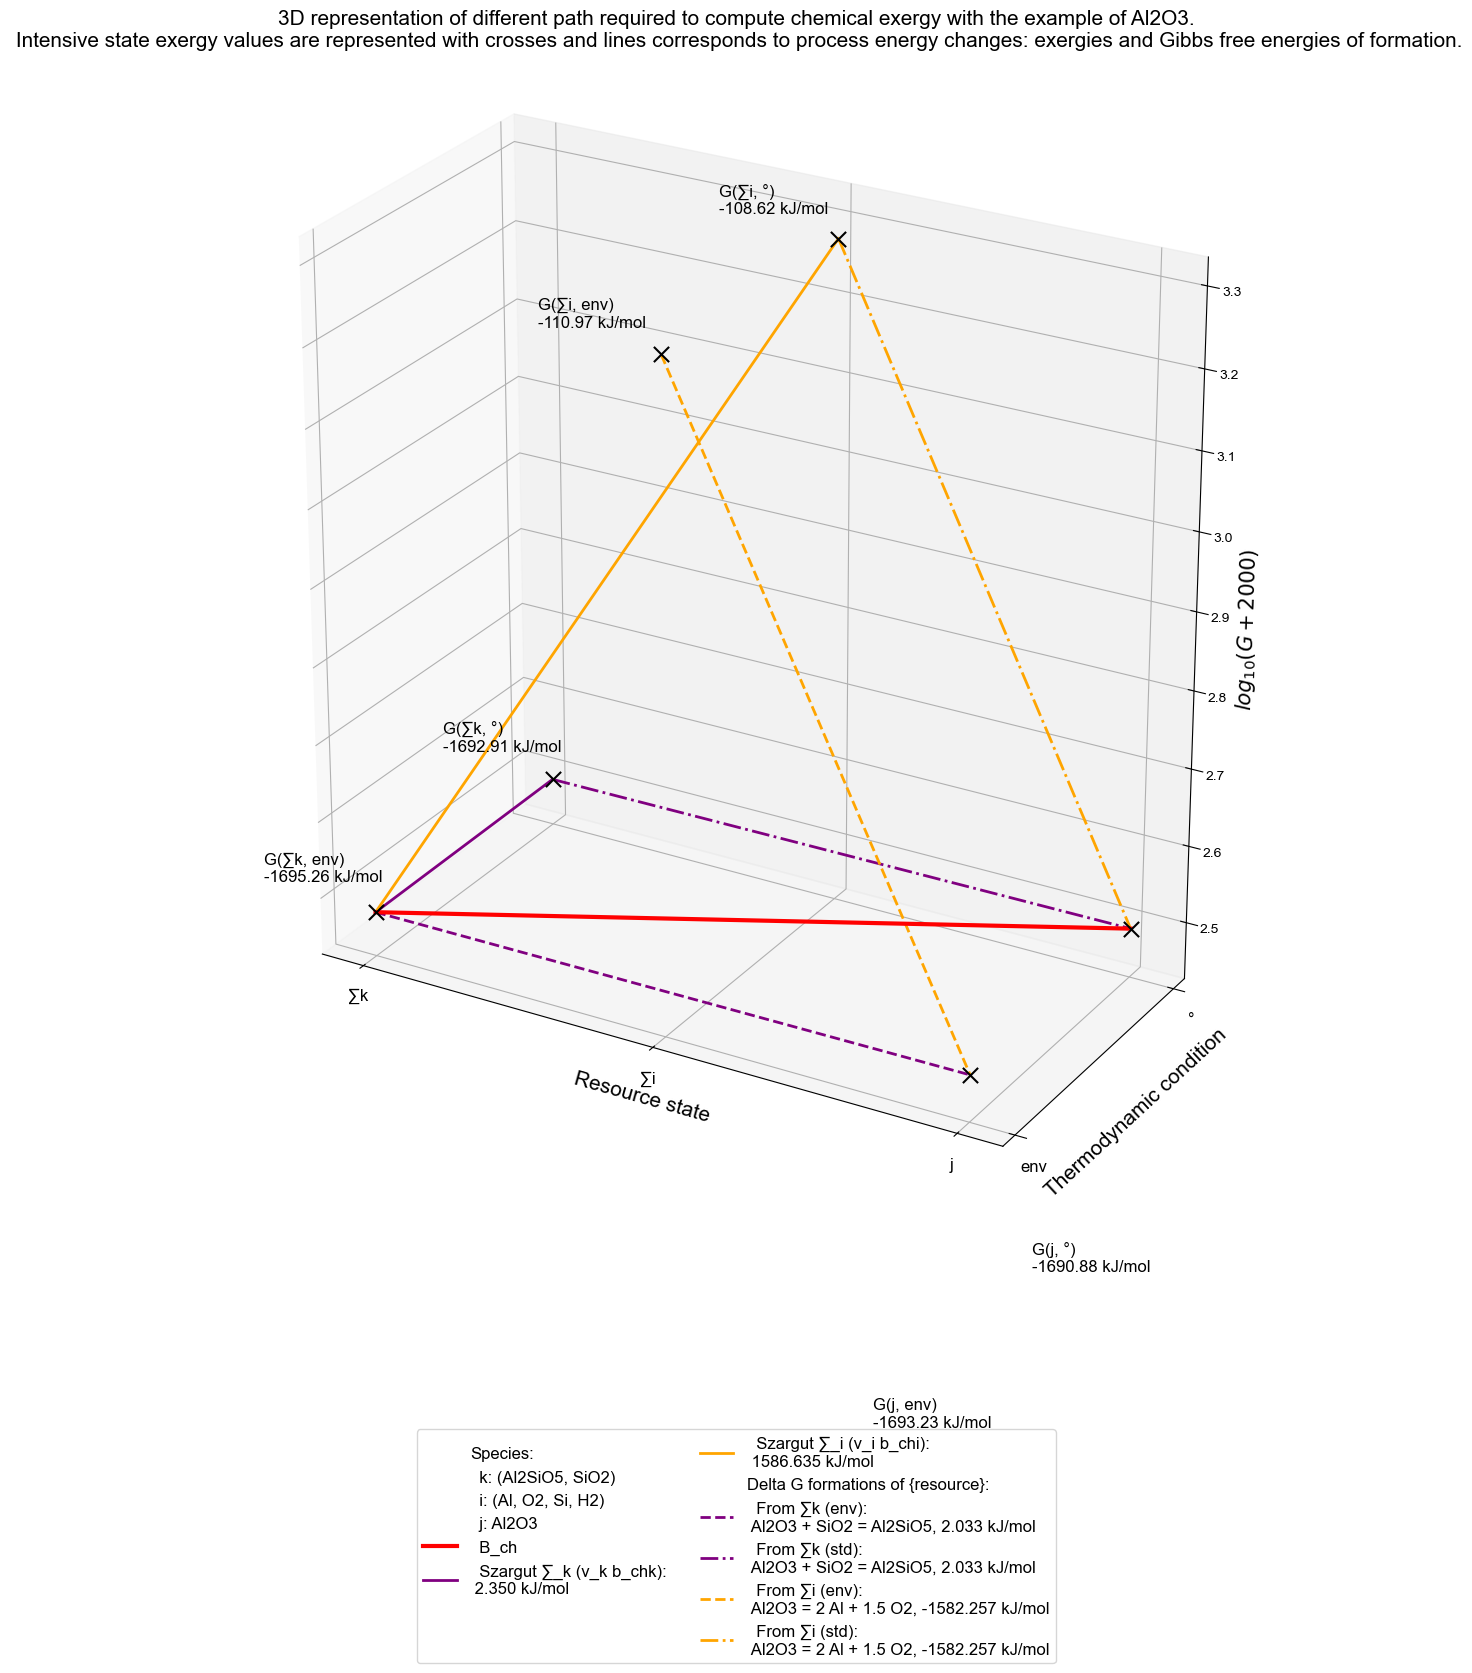

In [11]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

plt.rcParams['font.family'] = 'Arial'

fontsize_title = 15
fontsize_legend = 12

def plot_exergy_state_space_log(
    results,
    reference_elements_k,
    reference_elements_i,
    resource,
    filename='exergy_Al2O3_plot_log.svg',
    title=None
):
    """Plot the 3D exergy state-space for one computed results set."""
    if title is None:
        title = f'3D representation of different path required to compute chemical exergy with the example of {resource}.\n Intensive state exergy values are represented with crosses and lines corresponds to process energy changes: exergies and Gibbs free energies of formation.'

    G_env_sumk_in_j = results['G_env_sumk_in_j']
    G_env_j = results['G_env_j']
    G_std_sumk_in_j = results['G_std_sumk_in_j']
    G_std_j = results['G_std_j']
    G_env_sumi_in_j = results['G_env_sumi_in_j']
    G_std_sumi_in_j = results['G_std_sumi_in_j']

    x_positions = {
        '∑k': 0,
        '∑i': 1,
        'j': 2
    }

    y_positions = {
        'env': 0,
        '°': 1
    }

    color_map = {
        '∑k': 'purple',
        '∑i': 'orange',
        'j': 'black'
    }

    points = [
        ('∑k', 'env', G_env_sumk_in_j),
        ('j', 'env', G_env_j),
        ('∑k', '°', G_std_sumk_in_j),
        ('j', '°', G_std_j),
        ('∑i', 'env', G_env_sumi_in_j),
        ('∑i', '°', G_std_sumi_in_j),
    ]

    def z_transform(G):
        shifted_G = G + 2000  # Shift to make all values positive
        return np.log10(shifted_G)  # Apply log10

    fig = plt.figure(figsize=(15, 15))
    ax = fig.add_subplot(111, projection='3d')

    for state, thermo, G in points:
        x = x_positions[state]
        y = y_positions[thermo]
        z = z_transform(G)

        ax.scatter(x, y, z, s=120, marker='x', color="black")

        dx = -0.4 if state in ['∑k', '∑i'] else -0.3
        dz = 0 if state in ['∑k', '∑i'] else -0.5
        ax.text(
            x + dx,
            y,
            z + dz,
            f"G({state}, {thermo})\n{G:.2f} kJ/mol",
            fontsize=fontsize_legend,
            color="black"
        )

    sum_k = '∑k'
    sum_i = '∑i'

    ax.plot(
        [x_positions['∑k'], x_positions['∑k']],
        [y_positions['env'], y_positions['°']],
        [
            z_transform(G_env_sumk_in_j),
            z_transform(G_std_sumk_in_j)
        ],
        linewidth=2,
        color='purple',
        label=None
    )

    ax.plot(
        [x_positions['∑k'], x_positions['∑i']],
        [y_positions['env'], y_positions['°']],
        [
            z_transform(G_env_sumk_in_j),
            z_transform(G_std_sumi_in_j)
        ],
        linewidth=2,
        color='orange',
        label=None
    )

    delta_G_k = G_env_j - G_env_sumk_in_j
    delta_G_i = G_env_j - G_env_sumi_in_j

    ax.plot(
        [x_positions['∑k'], x_positions['j']],
        [y_positions['env'], y_positions['env']],
        [
            z_transform(G_env_sumk_in_j),
            z_transform(G_env_j)
        ],
        linestyle='--',
        linewidth=2,
        color='purple',
        label=None
    )

    ax.plot(
        [x_positions['∑k'], x_positions['j']],
        [y_positions['°'], y_positions['°']],
        [
            z_transform(G_std_sumk_in_j),
            z_transform(G_std_j)
        ],
        linestyle='-.',
        linewidth=2,
        color='purple',
        label=None
    )

    ax.plot(
        [x_positions['∑i'], x_positions['j']],
        [y_positions['env'], y_positions['env']],
        [
            z_transform(G_env_sumi_in_j),
            z_transform(G_env_j)
        ],
        linestyle='--',
        linewidth=2,
        color='orange',
        label=None
    )

    ax.plot(
        [x_positions['∑i'], x_positions['j']],
        [y_positions['°'], y_positions['°']],
        [
            z_transform(G_std_sumi_in_j),
            z_transform(G_std_j)
        ],
        linestyle='-.',
        linewidth=2,
        color='orange',
        label=None
    )

    ax.plot(
        [x_positions['∑k'], x_positions['j']],
        [y_positions['env'], y_positions['°']],
        [
            z_transform(G_env_sumk_in_j),
            z_transform(G_std_j)
        ],
        color='red',
        linewidth=3,
        label=None
    )

    B_ch = G_std_j - G_env_sumk_in_j
    b_chk = results.get('B_sumk_in_j', None)
    b_chi = results.get('B_sumi_in_j', None)

    bch_label_z = G_env_sumk_in_j  
    ax.text(
        x_positions['∑i'] + 0.2,
        y_positions['°'] - 1.5,
        bch_label_z + 500,
        f"B_ch = {B_ch:.3f} kJ/mol",
        color='red',
        fontsize=fontsize_legend
    )

    ax.set_xlabel('Resource state', fontsize=fontsize_title)
    ax.set_ylabel('Thermodynamic condition', fontsize=fontsize_title)

    ax.set_zlabel(r'$log_{10}(G + 2000)$', fontsize=fontsize_title)

    ax.set_xticks(list(x_positions.values()))
    ax.set_xticklabels(list(x_positions.keys()), fontsize=fontsize_legend)
    ax.set_yticks(list(y_positions.values()))
    ax.set_yticklabels(list(y_positions.keys()), fontsize=fontsize_legend)
    ax.set_box_aspect((2, 1, 2))
    ax.view_init(elev=25, azim=-60)

    plt.title(title, fontsize=fontsize_title)

    import matplotlib.lines as mlines
    handles = []
    labels = []

    labels.append('Species:')
    handles.append(mlines.Line2D([0], [0], linestyle='None', marker='None'))

    labels.append(f'  k: ({", ".join(reference_elements_k)})')
    handles.append(mlines.Line2D([0], [0], linestyle='None', marker='None'))

    labels.append(f'  i: ({", ".join(reference_elements_i)})')
    handles.append(mlines.Line2D([0], [0], linestyle='None', marker='None'))

    labels.append(f'  j: {resource}')
    handles.append(mlines.Line2D([0], [0], linestyle='None', marker='None'))

    labels.append('  B_ch')
    handles.append(mlines.Line2D([0], [0], color='red', linewidth=3))

    labels.append(f'  Szargut ∑_k (ν_k b_chk):\n {b_chk:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='purple', linewidth=2))

    labels.append(f'  Szargut ∑_i (ν_i b_chi):\n {b_chi:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='orange', linewidth=2))

    labels.append('Delta G formations of {resource}:')
    handles.append(mlines.Line2D([0], [0], linestyle='None', marker='None'))

    labels.append(f'  From {sum_k} (env):\n Al2O3 + SiO2 = Al2SiO5, {delta_G_k:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='purple', linestyle='--', linewidth=2))

    labels.append(f'  From {sum_k} (std):\n Al2O3 + SiO2 = Al2SiO5, {delta_G_k:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='purple', linestyle='-.', linewidth=2))

    labels.append(f'  From {sum_i} (env):\n Al2O3 = 2 Al + 1.5 O2, {delta_G_i:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='orange', linestyle='--', linewidth=2))

    labels.append(f'  From {sum_i} (std):\n Al2O3 = 2 Al + 1.5 O2, {delta_G_i:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='orange', linestyle='-.', linewidth=2))

    ax.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.4), ncol=2, fontsize=fontsize_legend)
    plt.tight_layout()
    plt.savefig(filename)
    plt.show()

plot_exergy_state_space_log(
    results_szargut,
    reference_elements_k=reference_environment_species_k_szargut,
    reference_elements_i=reference_elements_i,
    resource=resource,    filename='exergy_abs_Al2O3_plot.svg'
)

### single results df: plot raw values scale

C:\Users\lfreboeuf\AppData\Local\Temp\ipykernel_34996\155947697.py:241: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


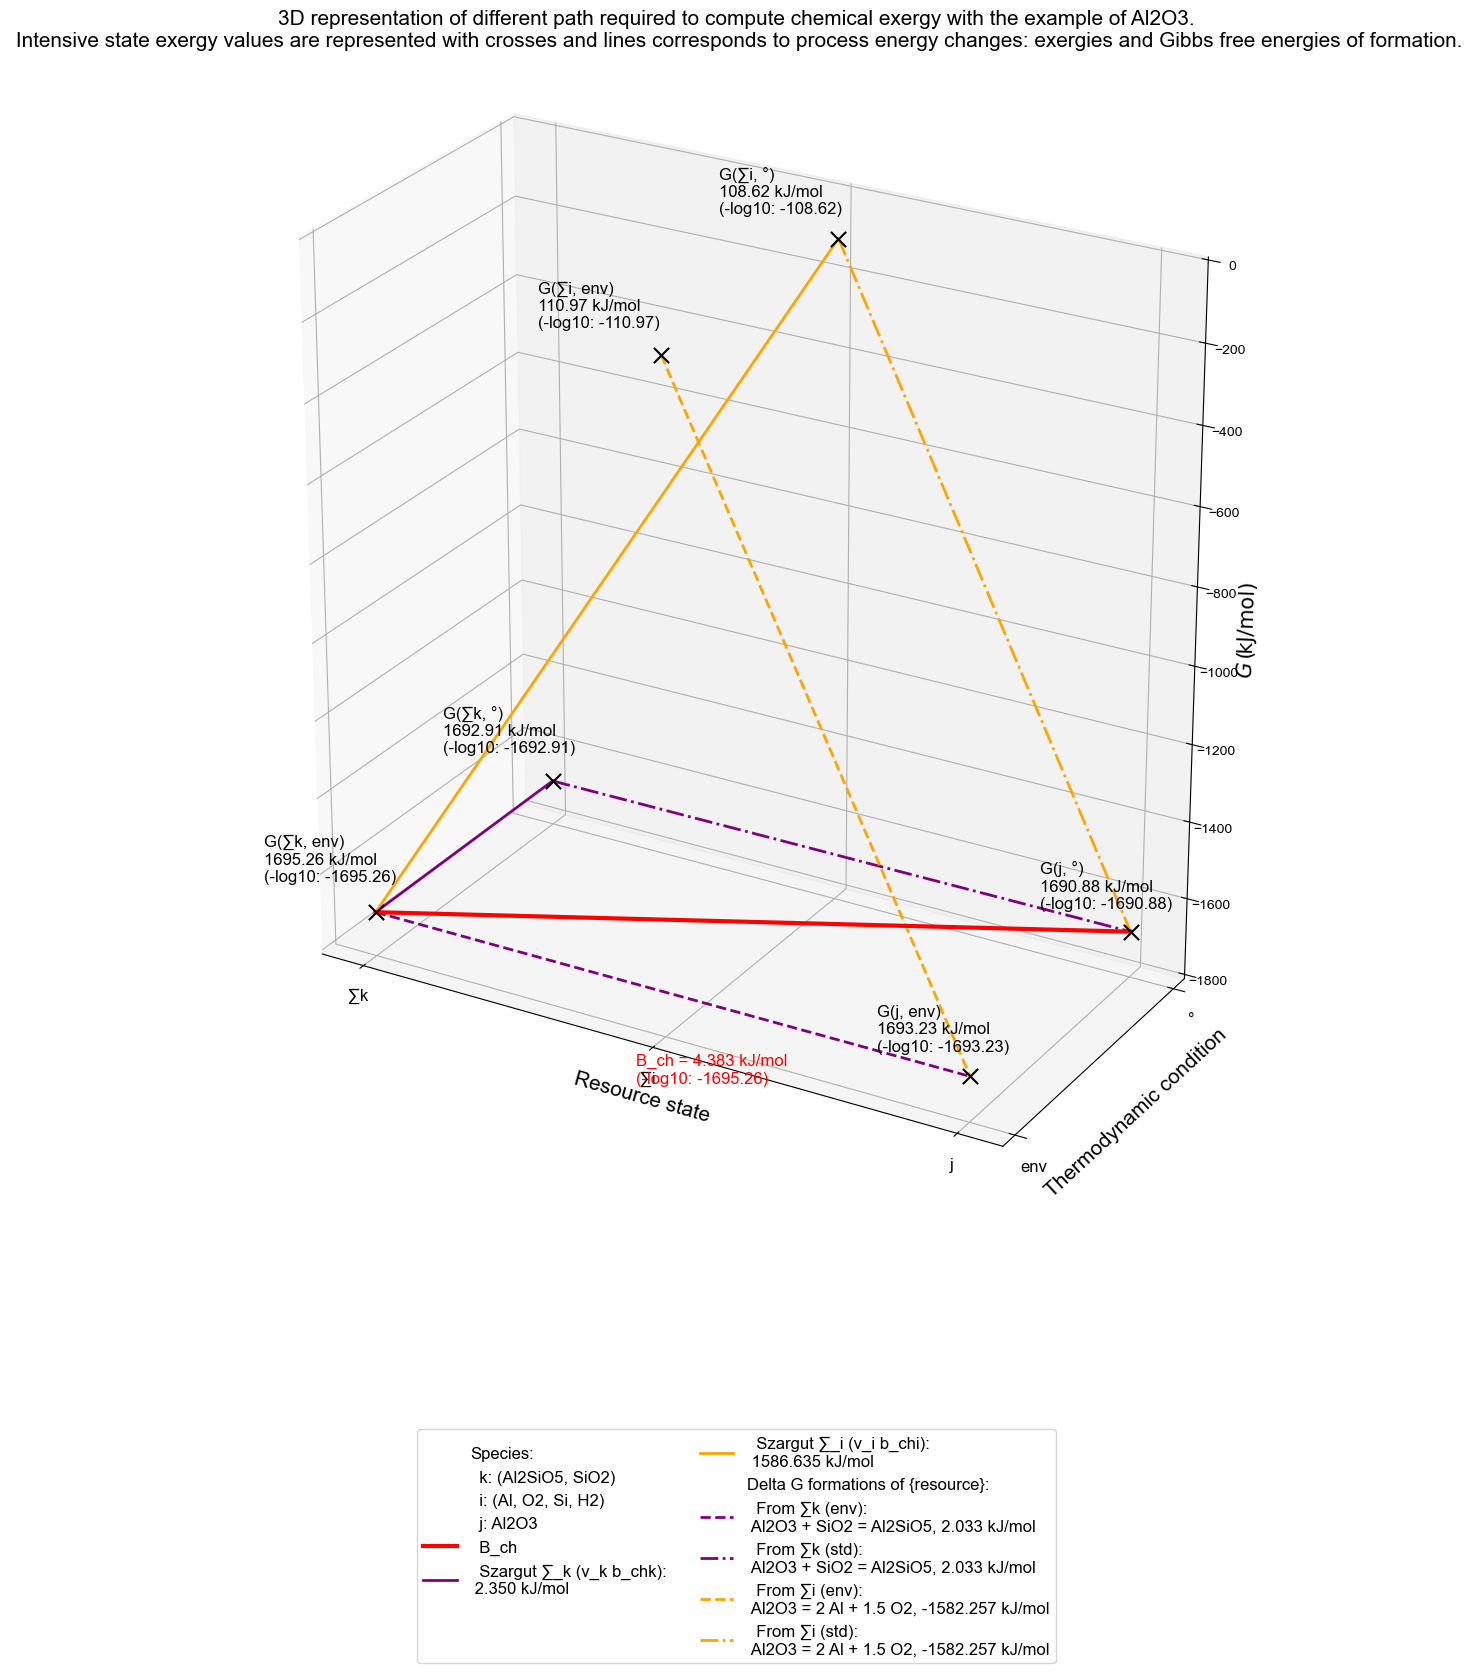

In [23]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

plt.rcParams['font.family'] = 'Arial'

fontsize_title = 15
fontsize_legend = 12

def plot_exergy_state_space_real(
    results,
    reference_elements_k,
    reference_elements_i,
    resource,
    filename='exergy_Al2O3_plot.svg',
    title=None
):
    """Plot the 3D exergy state-space for one computed results set."""
    if title is None:
        title = f'3D representation of different path required to compute chemical exergy with the example of {resource}.\n Intensive state exergy values are represented with crosses and lines corresponds to process energy changes: exergies and Gibbs free energies of formation.'

    G_env_sumk_in_j = results['G_env_sumk_in_j']
    G_env_j = results['G_env_j']
    G_std_sumk_in_j = results['G_std_sumk_in_j']
    G_std_j = results['G_std_j']
    G_env_sumi_in_j = results['G_env_sumi_in_j']
    G_std_sumi_in_j = results['G_std_sumi_in_j']

    x_positions = {
        '∑k': 0,
        '∑i': 1,
        'j': 2
    }

    y_positions = {
        'env': 0,
        '°': 1
    }

    color_map = {
        '∑k': 'purple',
        '∑i': 'orange',
        'j': 'black'
    }

    points = [
        ('∑k', 'env', G_env_sumk_in_j),
        ('j', 'env', G_env_j),
        ('∑k', '°', G_std_sumk_in_j),
        ('j', '°', G_std_j),
        ('∑i', 'env', G_env_sumi_in_j),
        ('∑i', '°', G_std_sumi_in_j),
    ]

    def z_transform(G):
        return (G)

    fig = plt.figure(figsize=(15, 15))
    ax = fig.add_subplot(111, projection='3d')

    for state, thermo, G in points:
        x = x_positions[state]
        y = y_positions[thermo]
        z = z_transform(G)

        ax.scatter(x, y, z, s=120, marker='x', color="black")

        dx = -0.4 if state in ['∑k', '∑i'] else -0.3
        dz = 0 if state in ['∑k', '∑i'] else -0.5
        ax.text(
            x + dx,
            y,
            z + dz,
            f"G({state}, {thermo})\n{abs(G):.2f} kJ/mol\n(-log10: {z:.2f})",  # Show both raw and transformed values
            fontsize=fontsize_legend,
            color="black"
        )       

    sum_k = '∑k'
    sum_i = '∑i'

    ax.plot(
        [x_positions['∑k'], x_positions['∑k']],
        [y_positions['env'], y_positions['°']],
        [
            z_transform(G_env_sumk_in_j),
            z_transform(G_std_sumk_in_j)
        ],
        linewidth=2,
        color='purple',
        label=None
    )

    ax.plot(
        [x_positions['∑k'], x_positions['∑i']],
        [y_positions['env'], y_positions['°']],
        [
            z_transform(G_env_sumk_in_j),
            z_transform(G_std_sumi_in_j)
        ],
        linewidth=2,
        color='orange',
        label=None
    )

    delta_G_k = G_env_j - G_env_sumk_in_j
    delta_G_i = G_env_j - G_env_sumi_in_j

    ax.plot(
        [x_positions['∑k'], x_positions['j']],
        [y_positions['env'], y_positions['env']],
        [
            z_transform(G_env_sumk_in_j),
            z_transform(G_env_j)
        ],
        linestyle='--',
        linewidth=2,
        color='purple',
        label=None
    )

    ax.plot(
        [x_positions['∑k'], x_positions['j']],
        [y_positions['°'], y_positions['°']],
        [
            z_transform(G_std_sumk_in_j),
            z_transform(G_std_j)
        ],
        linestyle='-.',
        linewidth=2,
        color='purple',
        label=None
    )

    ax.plot(
        [x_positions['∑i'], x_positions['j']],
        [y_positions['env'], y_positions['env']],
        [
            z_transform(G_env_sumi_in_j),
            z_transform(G_env_j)
        ],
        linestyle='--',
        linewidth=2,
        color='orange',
        label=None
    )

    ax.plot(
        [x_positions['∑i'], x_positions['j']],
        [y_positions['°'], y_positions['°']],
        [
            z_transform(G_std_sumi_in_j),
            z_transform(G_std_j)
        ],
        linestyle='-.',
        linewidth=2,
        color='orange',
        label=None
    )

    ax.plot(
        [x_positions['∑k'], x_positions['j']],
        [y_positions['env'], y_positions['°']],
        [
            z_transform(G_env_sumk_in_j),
            z_transform(G_std_j)
        ],
        color='red',
        linewidth=3,
        label=None
    )

    B_ch = G_std_j - G_env_sumk_in_j
    b_chk = results.get('B_sumk_in_j', None)
    b_chi = results.get('B_sumi_in_j', None)

    bch_label_z = z_transform(G_env_sumk_in_j)  # Use transformed value
    ax.text(
        x_positions['∑i'] + 0.2,
        y_positions['°'] - 1.5,
        bch_label_z + 0.5,  # Adjust offset for transformed scale
        f"B_ch = {B_ch:.3f} kJ/mol\n(-log10: {bch_label_z:.2f})",
        color='red',
        fontsize=fontsize_legend
    )

    ax.set_xlabel('Resource state', fontsize=fontsize_title)
    ax.set_ylabel('Thermodynamic condition', fontsize=fontsize_title)
    ax.set_zlabel(r'$G\, (\mathrm{\!kJ/mol})$', fontsize=fontsize_title)

    ax.set_xticks(list(x_positions.values()))
    ax.set_xticklabels(list(x_positions.keys()), fontsize=fontsize_legend)
    ax.set_yticks(list(y_positions.values()))
    ax.set_yticklabels(list(y_positions.keys()), fontsize=fontsize_legend)
    ax.set_box_aspect((2, 1, 2))
    ax.view_init(elev=25, azim=-60)

    plt.title(title, fontsize=fontsize_title)

    import matplotlib.lines as mlines
    handles = []
    labels = []

    labels.append('Species:')
    handles.append(mlines.Line2D([0], [0], linestyle='None', marker='None'))

    labels.append(f'  k: ({", ".join(reference_elements_k)})')
    handles.append(mlines.Line2D([0], [0], linestyle='None', marker='None'))

    labels.append(f'  i: ({", ".join(reference_elements_i)})')
    handles.append(mlines.Line2D([0], [0], linestyle='None', marker='None'))

    labels.append(f'  j: {resource}')
    handles.append(mlines.Line2D([0], [0], linestyle='None', marker='None'))

    labels.append('  B_ch')
    handles.append(mlines.Line2D([0], [0], color='red', linewidth=3))

    labels.append(f'  Szargut ∑_k (ν_k b_chk):\n {b_chk:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='purple', linewidth=2))

    labels.append(f'  Szargut ∑_i (ν_i b_chi):\n {b_chi:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='orange', linewidth=2))

    labels.append('Delta G formations of {resource}:')
    handles.append(mlines.Line2D([0], [0], linestyle='None', marker='None'))

    labels.append(f'  From {sum_k} (env):\n Al2O3 + SiO2 = Al2SiO5, {delta_G_k:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='purple', linestyle='--', linewidth=2))

    labels.append(f'  From {sum_k} (std):\n Al2O3 + SiO2 = Al2SiO5, {delta_G_k:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='purple', linestyle='-.', linewidth=2))

    labels.append(f'  From {sum_i} (env):\n Al2O3 = 2 Al + 1.5 O2, {delta_G_i:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='orange', linestyle='--', linewidth=2))

    labels.append(f'  From {sum_i} (std):\n Al2O3 = 2 Al + 1.5 O2, {delta_G_i:.3f} kJ/mol')
    handles.append(mlines.Line2D([0], [0], color='orange', linestyle='-.', linewidth=2))

    ax.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.4), ncol=2, fontsize=fontsize_legend)
    plt.tight_layout()
    plt.savefig(filename)
    plt.show()

plot_exergy_state_space_real(
    results_szargut,
    reference_elements_k=reference_environment_species_k_szargut,
    reference_elements_i=reference_elements_i,
    resource=resource,    
    filename='exergy_abs_Al2O3_plot.svg'
)

## all 6Gs, B_ch

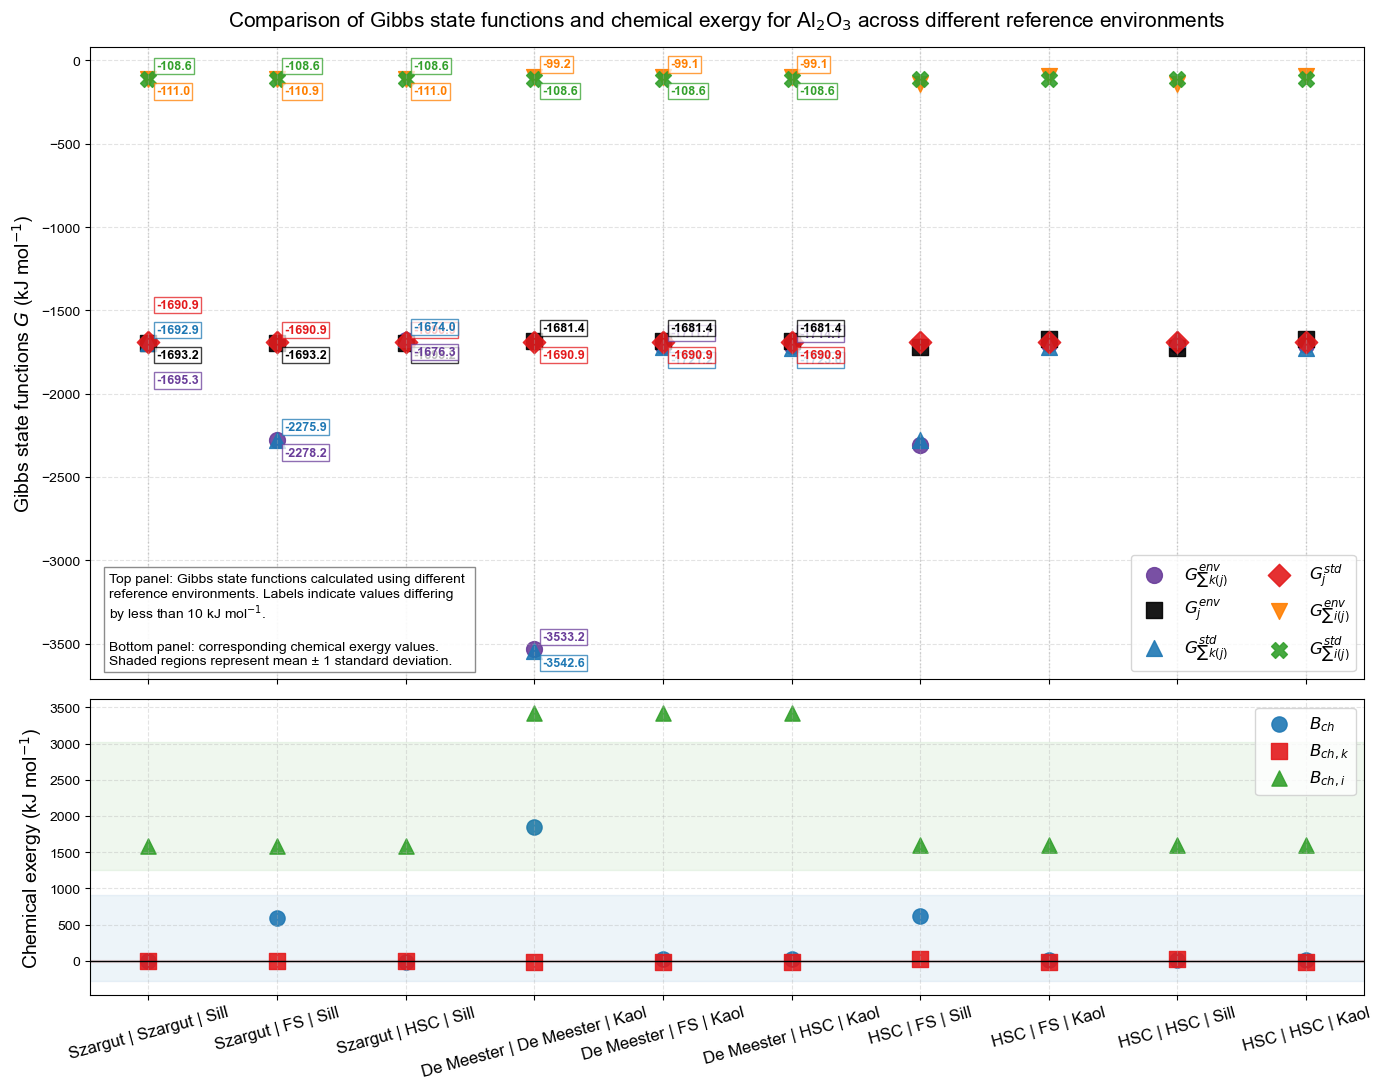

,method,G_env_sumk_in_j,G_env_j,G_std_sumk_in_j,G_std_j,G_env_sumi_in_j,G_std_sumi_in_j,B_ch,B_chk,B_chi
0,Szargut | Szargut | Sill,-1695.263499,-1693.230499,-1692.913499,-1690.880499,-110.973499,-108.623499,4.3830,2.35,1586.635
1,Szargut | FS | Sill,-2278.228023,-1693.202023,-2275.878023,-1690.852023,-110.908323,-108.558323,587.3760,2.35,1586.635
2,Szargut | HSC | Sill,-1676.320144,-1693.232144,-1673.970144,-1690.882144,-110.958144,-108.608144,-14.5620,2.35,1586.635
3,De Meester | De Meester | Kaol,-3533.163499,-1681.420499,-3542.623499,-1690.880499,-99.163499,-108.623499,1842.2830,-9.46,3424.550
4,De Meester | FS | Kaol,-1711.737923,-1681.392023,-1721.197923,-1690.852023,-99.098323,-108.558323,20.8859,-9.46,3424.550
5,De Meester | HSC | Kaol,-1714.109144,-1681.422144,-1723.569144,-1690.882144,-99.148144,-108.608144,23.2270,-9.46,3424.550
6,HSC | FS | Sill,-2307.798023,-1722.772023,-2275.878023,-1690.852023,-140.478323,-108.558323,616.9460,31.92,1597.280
7,HSC | FS | Kaol,-1703.527923,-1673.182023,-1721.197923,-1690.852023,-90.888323,-108.558323,12.6759,-17.67,1597.280
8,HSC | HSC | Sill,-1705.890144,-1722.802144,-1673.970144,-1690.882144,-140.528144,-108.608144,15.0080,31.92,1597.280
9,HSC | HSC | Kaol,-1705.899144,-1673.212144,-1723.569144,-1690.882144,-90.938144,-108.608144,15.0170,-17.67,1597.280


In [25]:
# ============================================================================
# COMPUTE ALL CONFIGURATIONS OF b_chi WITH NEW CONFIGURATIONS
# ============================================================================

# Define all possible configurations with short labels
configurations = [
    {
        "name": "Szargut + Szargut",
        "chem_exergy_source": "Szargut",
        "DeltafrG_source": "Szargut",
        "env_species_Al": "Sillimanite",
        "short_label": "Szargut | Szargut | Sill",
        "chem_exergy_k": szargut_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_szargut_brgm,
        "b_chk_init": szargut_chem_exergy_i,
        "env_species_order": ["SiO2", "Al2SiO5"],
    },
    {
        "name": "Szargut + FactSage",
        "chem_exergy_source": "Szargut",
        "DeltafrG_source": "FactSage",
        "env_species_Al": "Sillimanite",
        "short_label": "Szargut | FS | Sill",
        "chem_exergy_k": szargut_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_FS,
        "b_chk_init": szargut_chem_exergy_i,
        "env_species_order": ["SiO2", "Al2SiO5"],
    },
    {
        "name": "Szargut + HSC",
        "chem_exergy_source": "Szargut",
        "DeltafrG_source": "HSC",
        "env_species_Al": "Sillimanite",
        "short_label": "Szargut | HSC | Sill",
        "chem_exergy_k": szargut_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_HSC,
        "b_chk_init": szargut_chem_exergy_i,
        "env_species_order": ["SiO2", "Al2SiO5"],
    },
    {
        "name": "De Meester + De Meester",
        "chem_exergy_source": "De Meester",
        "DeltafrG_source": "De Meester",
        "env_species_Al": "Kaolinite",
        "short_label": "De Meester | De Meester | Kaol",
        "chem_exergy_k": demeester_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_demeester_brgm,
        "b_chk_init": demeester_chem_exergy_i,
        "env_species_order": ["SiO2", "H2O", "Al2Si2O5(OH)4"],
    },
    {
        "name": "De Meester + FactSage",
        "chem_exergy_source": "De Meester",
        "DeltafrG_source": "FactSage",
        "env_species_Al": "Kaolinite",
        "short_label": "De Meester | FS | Kaol",
        "chem_exergy_k": demeester_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_FS,
        "b_chk_init": demeester_chem_exergy_i,
        "env_species_order": ["SiO2", "H2O", "Al2Si2O5(OH)4"],
    },
    {
        "name": "De Meester + HSC",
        "chem_exergy_source": "De Meester",
        "DeltafrG_source": "HSC",
        "env_species_Al": "Kaolinite",
        "short_label": "De Meester | HSC | Kaol",
        "chem_exergy_k": demeester_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_HSC,
        "b_chk_init": demeester_chem_exergy_i,
        "env_species_order": ["SiO2", "H2O", "Al2Si2O5(OH)4"],
    },
    {
        "name": "HSC + FactSage (Sillimanite)",
        "chem_exergy_source": "HSC",
        "DeltafrG_source": "FactSage",
        "env_species_Al": "Sillimanite",
        "short_label": "HSC | FS | Sill",
        "chem_exergy_k": HSC_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_FS,
        "b_chk_init": HSC_chem_exergy_i,
        "env_species_order": ["SiO2", "Al2SiO5"],
    },
    {
        "name": "HSC + FactSage (Kaolinite)",
        "chem_exergy_source": "HSC",
        "DeltafrG_source": "FactSage",
        "env_species_Al": "Kaolinite",
        "short_label": "HSC | FS | Kaol",
        "chem_exergy_k": HSC_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_FS,
        "b_chk_init": HSC_chem_exergy_i,
        "env_species_order": ["SiO2", "H2O", "Al2Si2O5(OH)4"],
    },
    {
        "name": "HSC + HSC (Sillimanite)",
        "chem_exergy_source": "HSC",
        "DeltafrG_source": "HSC",
        "env_species_Al": "Sillimanite",
        "short_label": "HSC | HSC | Sill",
        "chem_exergy_k": HSC_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_HSC,
        "b_chk_init": HSC_chem_exergy_i,
        "env_species_order": ["SiO2", "Al2SiO5"],
    },
    {
        "name": "HSC + HSC (Kaolinite)",
        "chem_exergy_source": "HSC",
        "DeltafrG_source": "HSC",
        "env_species_Al": "Kaolinite",
        "short_label": "HSC | HSC | Kaol",
        "chem_exergy_k": HSC_chem_exergy_k,
        "DeltafrG_std": DeltafrG_std_HSC,
        "b_chk_init": HSC_chem_exergy_i,
        "env_species_order": ["SiO2", "H2O", "Al2Si2O5(OH)4"],
    },
]

# =============================================================================
# BUILD DATAFRAME
# =============================================================================

def build_exergy_dataframe(results_dict):
    """
    Convert all methods results into a dataframe.
    """

    rows = []

    for method_name, results in results_dict.items():

        B_ch = results['G_std_j'] - results['G_env_sumk_in_j']

        row = {
            'method': method_name,

            'G_env_sumk_in_j': results['G_env_sumk_in_j'],
            'G_env_j': results['G_env_j'],
            'G_std_sumk_in_j': results['G_std_sumk_in_j'],
            'G_std_j': results['G_std_j'],
            'G_env_sumi_in_j': results['G_env_sumi_in_j'],
            'G_std_sumi_in_j': results['G_std_sumi_in_j'],

            'B_ch': B_ch,
            'B_chk': results.get('B_sumk_in_j', np.nan),
            'B_chi': results.get('B_sumi_in_j', np.nan),
        }

        rows.append(row)

    df = pd.DataFrame(rows)

    return df

# =============================================================================
# PLOT — G STATE FUNCTIONS + CHEMICAL EXERGY
# =============================================================================

def plot_exergy_comparison(
    df,
    filename='G_and_exergy_comparison.svg',
    similarity_threshold=10 # kJ/mol
):

    # -------------------------------------------------------------------------
    # FIGURE
    # -------------------------------------------------------------------------

    fig, (ax1, ax2) = plt.subplots(
        2,
        1,
        figsize=(14, 11),
        sharex=True,
        gridspec_kw={'height_ratios': [3, 1.4]}
    )

    methods = df['method'].tolist()
    x = np.arange(len(methods))

    # -------------------------------------------------------------------------
    # G STATE FUNCTIONS
    # -------------------------------------------------------------------------

    G_columns = [
        'G_env_sumk_in_j',
        'G_env_j',
        'G_std_sumk_in_j',
        'G_std_j',
        'G_env_sumi_in_j',
        'G_std_sumi_in_j'
    ]

    G_labels = [
        r'$G_{\sum k(j)}^{env}$',
        r'$G_{j}^{env}$',
        r'$G_{\sum k(j)}^{std}$',
        r'$G_{j}^{std}$',
        r'$G_{\sum i(j)}^{env}$',
        r'$G_{\sum i(j)}^{std}$'
    ]

    G_colors = [
        '#6a3d9a',
        '#000000',
        '#1f78b4',
        '#e31a1c',
        '#ff7f00',
        '#33a02c'
    ]

    G_markers = ['o', 's', '^', 'D', 'v', 'X']

    # -------------------------------------------------------------------------
    # STORE POINT DATA
    # -------------------------------------------------------------------------

    point_data = []

    # -------------------------------------------------------------------------
    # PLOT G VALUES
    # -------------------------------------------------------------------------

    for col, label, color, marker in zip(
        G_columns,
        G_labels,
        G_colors,
        G_markers
    ):

        y = df[col].values

        ax1.scatter(
            x,
            y,
            marker=marker,
            s=130,
            color=color,
            label=label,
            alpha=0.9
        )

        for xi, yi in zip(x, y):

            point_data.append({
                'x': xi,
                'y': yi,
                'color': color
            })

    # -------------------------------------------------------------------------
    # LABEL VERY SIMILAR VALUES
    # -------------------------------------------------------------------------

    # -------------------------------------------------------------------------
    # LABEL CLUSTERS OF VERY SIMILAR VALUES
    # -------------------------------------------------------------------------

    for xi in x:

        local_points = [
            p for p in point_data
            if p['x'] == xi
        ]

        # sort by y value
        local_points = sorted(local_points, key=lambda p: p['y'])

        clusters = []
        current_cluster = [local_points[0]]

        # build clusters of nearby points
        for p in local_points[1:]:

            if abs(p['y'] - current_cluster[-1]['y']) < similarity_threshold:

                current_cluster.append(p)

            else:

                clusters.append(current_cluster)
                current_cluster = [p]

        clusters.append(current_cluster)

        # ---------------------------------------------------------------------
        # LABEL CLUSTERS
        # ---------------------------------------------------------------------

        for cluster in clusters:

            # only annotate clusters with at least 2 nearby values
            if len(cluster) >= 2:

                for idx, p in enumerate(cluster):

                    # symmetric offsets around point
                    offset = (idx - (len(cluster)-1)/2) * 150

                    ax1.text(
                        p['x'] + 0.06,
                        p['y'] + offset,
                        f'{p["y"]:.1f}',
                        fontsize=9,
                        color=p['color'],
                        va='center',
                        fontweight='bold',
                        bbox=dict(
                            facecolor='white',
                            edgecolor=p['color'],
                            alpha=0.75,
                            pad=1.5
                        )
                    )
    # -------------------------------------------------------------------------
    # GUIDE LINES
    # -------------------------------------------------------------------------

    for xi in x:

        ax1.axvline(
            xi,
            color='lightgray',
            linestyle=':',
            linewidth=1,
            zorder=0
        )

    # -------------------------------------------------------------------------
    # TOP PANEL FORMAT
    # -------------------------------------------------------------------------

    ax1.set_ylabel(
        r'Gibbs state functions $G$ (kJ mol$^{-1}$)',
        fontsize=fontsize_label
    )

    ax1.set_title(
        r'Comparison of Gibbs state functions and chemical exergy '
        r'for Al$_2$O$_3$ across different reference environments',
        fontsize=fontsize_title,
        pad=15
    )

    ax1.grid(
        linestyle='--',
        alpha=0.35
    )

    ax1.legend(
        fontsize=fontsize_legend,
        ncol=2,
        frameon=True
    )

    # -------------------------------------------------------------------------
    # CHEMICAL EXERGY PANEL
    # -------------------------------------------------------------------------

    exergy_columns = [
        'B_ch',
        'B_chk',
        'B_chi'
    ]

    exergy_labels = [
        r'$B_{ch}$',
        r'$B_{ch,k}$',
        r'$B_{ch,i}$'
    ]

    exergy_colors = [
        '#1f78b4',
        '#e31a1c',
        '#33a02c'
    ]

    exergy_markers = ['o', 's', '^']

    for col, label, color, marker in zip(
        exergy_columns,
        exergy_labels,
        exergy_colors,
        exergy_markers
    ):

        ax2.scatter(
            x,
            df[col],
            marker=marker,
            s=120,
            color=color,
            label=label,
            alpha=0.9
        )

        # variability envelope
        mean = df[col].mean()
        std = df[col].std(ddof=1)

        ax2.axhspan(
            mean - std,
            mean + std,
            alpha=0.08,
            color=color
        )

    # -------------------------------------------------------------------------
    # BOTTOM PANEL FORMAT
    # -------------------------------------------------------------------------

    ax2.axhline(
        0,
        color='black',
        linewidth=1
    )

    ax2.grid(
        linestyle='--',
        alpha=0.35
    )

    ax2.set_ylabel(
        r'Chemical exergy (kJ mol$^{-1}$)',
        fontsize=fontsize_label
    )

    ax2.set_xticks(x)

    ax2.set_xticklabels(
        methods,
        rotation=15,
        fontsize=fontsize_ticks
    )

    ax2.legend(
        fontsize=fontsize_legend,
        loc='best'
    )

    # -------------------------------------------------------------------------
    # CAPTION
    # -------------------------------------------------------------------------

    txt = (
        r'Top panel: Gibbs state functions calculated using different '
        '\nreference environments. Labels indicate values differing '
        f'\nby less than {similarity_threshold} kJ mol$^{{-1}}$.'
        '\n'
        '\nBottom panel: corresponding chemical exergy values.'
        '\nShaded regions represent mean ± 1 standard deviation.'
    )

    ax1.text(
        0.015,
        0.02,
        txt,
        transform=ax1.transAxes,
        fontsize=10,
        verticalalignment='bottom',
        bbox=dict(
            facecolor='white',
            edgecolor='gray',
            alpha=0.9
        )
    )

    # -------------------------------------------------------------------------
    # LAYOUT
    # -------------------------------------------------------------------------

    plt.tight_layout()

    plt.savefig(
        filename,
        dpi=600,
        bbox_inches='tight'
    )

    plt.show()


# Compute results for all configurations
results_all_complete = {}
for config in configurations:
    try:
        results = compute_all_G_values(
            DeltafrG_std=config["DeltafrG_std"],
            S_std=S_std_FS if "FactSage" in config["DeltafrG_source"] else (S_std_HSC if "HSC" in config["DeltafrG_source"] else S_std_brgm),
            H_std=H_std,
            G_std=G_std,
            resource=resource,
            reference_elements_i=reference_elements_i,
            reference_species_k=config["env_species_order"],
            reaction_formation_j_from_i=reaction_formation_jfromis_sc,
            reaction_formation_j_from_k=reaction_formation_jfromks_sc_szargut if "Sillimanite" in config["env_species_Al"] else reaction_formation_jfromks_sc_demeester,
            chem_exergy_k=config["chem_exergy_k"],
            chem_exergy_i=config["b_chk_init"],
            Tenv=Tenv,
            standard_state_equivalencies=standard_state_equivalencies
        )
        results_all_complete[config["short_label"]] = results
    except Exception as e:
        print(f"Error computing results for {config['name']}: {e}")
        results_all_complete[config["short_label"]] = None

# Build dataframe and plot
df_exergy_complete = build_exergy_dataframe(results_all_complete)
plot_exergy_comparison(
    df_exergy_complete,
    filename='G_and_exergy_comparison_complete.svg'
)

# Show the dataframe
df_exergy_complete

## all 6Gs, B_ch, DeltaG

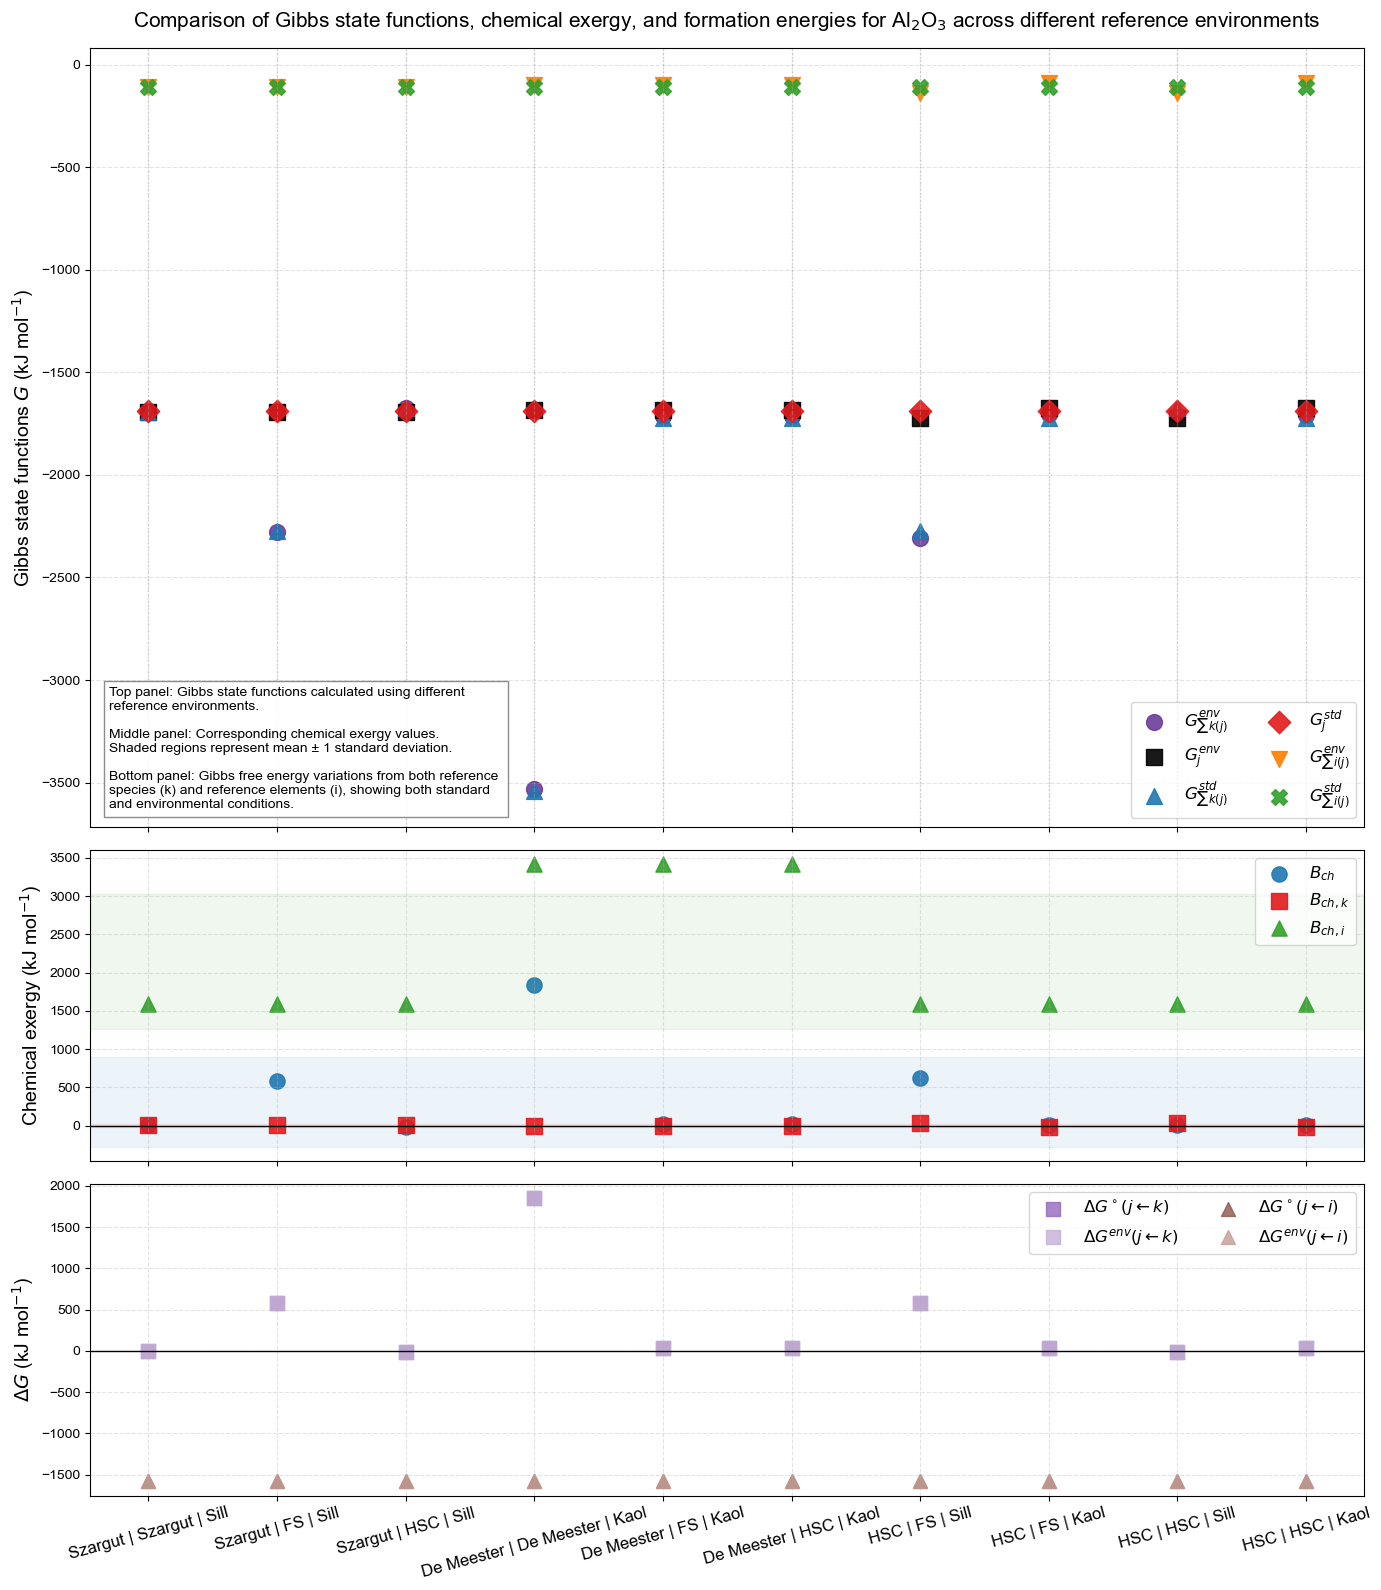

In [30]:
# ============================================================================
# ENHANCED PLOT WITH GIBBS FREE ENERGY VARIATIONS
# ============================================================================

def plot_enhanced_exergy_comparison(
    df,
    filename='enhanced_exergy_comparison.svg',
    similarity_threshold=10 # kJ/mol
):
    """Enhanced plot showing Gibbs free energy variations from both k and i references"""

    # -------------------------------------------------------------------------
    # FIGURE SETUP
    # -------------------------------------------------------------------------

    fig, (ax1, ax2, ax3) = plt.subplots(
        3,
        1,
        figsize=(14, 16),
        sharex=True,
        gridspec_kw={'height_ratios': [3, 1.2, 1.2]}
    )

    methods = df['method'].tolist()
    x = np.arange(len(methods))

    # -------------------------------------------------------------------------
    # G STATE FUNCTIONS (TOP PANEL - SAME AS BEFORE)
    # -------------------------------------------------------------------------

    G_columns = [
        'G_env_sumk_in_j',
        'G_env_j',
        'G_std_sumk_in_j',
        'G_std_j',
        'G_env_sumi_in_j',
        'G_std_sumi_in_j'
    ]

    G_labels = [
        r'$G_{\sum k(j)}^{env}$',
        r'$G_{j}^{env}$',
        r'$G_{\sum k(j)}^{std}$',
        r'$G_{j}^{std}$',
        r'$G_{\sum i(j)}^{env}$',
        r'$G_{\sum i(j)}^{std}$'
    ]

    G_colors = [
        '#6a3d9a',
        '#000000',
        '#1f78b4',
        '#e31a1c',
        '#ff7f00',
        '#33a02c'
    ]

    G_markers = ['o', 's', '^', 'D', 'v', 'X']

    # Plot G values (same as before)
    for col, label, color, marker in zip(G_columns, G_labels, G_colors, G_markers):
        y = df[col].values
        ax1.scatter(x, y, marker=marker, s=130, color=color, label=label, alpha=0.9)

    # Add guide lines
    for xi in x:
        ax1.axvline(xi, color='lightgray', linestyle=':', linewidth=1, zorder=0)

    # Formatting
    ax1.set_ylabel(r'Gibbs state functions $G$ (kJ mol$^{-1}$)', fontsize=fontsize_label)
    ax1.set_title(
        r'Comparison of Gibbs state functions, chemical exergy, and formation energies '
        r'for Al$_2$O$_3$ across different reference environments',
        fontsize=fontsize_title,
        pad=15
    )
    ax1.grid(linestyle='--', alpha=0.35)
    ax1.legend(fontsize=fontsize_legend, ncol=2, frameon=True)

    # -------------------------------------------------------------------------
    # CHEMICAL EXERGY PANEL (MIDDLE)
    # -------------------------------------------------------------------------

    exergy_columns = ['B_ch', 'B_chk', 'B_chi']
    exergy_labels = [r'$B_{ch}$', r'$B_{ch,k}$', r'$B_{ch,i}$']
    exergy_colors = ['#1f78b4', '#e31a1c', '#33a02c']
    exergy_markers = ['o', 's', '^']

    for col, label, color, marker in zip(exergy_columns, exergy_labels, exergy_colors, exergy_markers):
        ax2.scatter(x, df[col], marker=marker, s=120, color=color, label=label, alpha=0.9)

        # variability envelope
        mean = df[col].mean()
        std = df[col].std(ddof=1)
        ax2.axhspan(mean - std, mean + std, alpha=0.08, color=color)

    ax2.axhline(0, color='black', linewidth=1)
    ax2.grid(linestyle='--', alpha=0.35)
    ax2.set_ylabel(r'Chemical exergy (kJ mol$^{-1}$)', fontsize=fontsize_label)
    ax2.legend(fontsize=fontsize_legend, loc='best')

    # -------------------------------------------------------------------------
    # GIBBS FREE ENERGY VARIATIONS (NEW BOTTOM PANEL)
    # -------------------------------------------------------------------------

    # Calculate ΔG values if not already in dataframe
    if 'DeltaG_std_jk' not in df.columns:
        df['DeltaG_std_jk'] = df['G_std_j'] - df['G_std_sumk_in_j']
    if 'DeltaG_env_jk' not in df.columns:
        df['DeltaG_env_jk'] = df['G_env_j'] - df['G_env_sumk_in_j']
    if 'DeltaG_std_ji' not in df.columns:
        df['DeltaG_std_ji'] = df['G_std_j'] - df['G_std_sumi_in_j']
    if 'DeltaG_env_ji' not in df.columns:
        df['DeltaG_env_ji'] = df['G_env_j'] - df['G_env_sumi_in_j']

    # Plot ΔG from k (environmental species)
    deltaG_k_std = df['DeltaG_std_jk'].values
    deltaG_k_env = df['DeltaG_env_jk'].values

    ax3.scatter(x, deltaG_k_std, marker='s', s=100, color='#9467bd',
               label=r'$\Delta G^\circ(j \leftarrow k)$', alpha=0.8)
    ax3.scatter(x, deltaG_k_env, marker='s', s=100, color='#c5b0d5',
               label=r'$\Delta G^{env}(j \leftarrow k)$', alpha=0.8)

    # Plot ΔG from i (reference elements)
    deltaG_i_std = df['DeltaG_std_ji'].values
    deltaG_i_env = df['DeltaG_env_ji'].values

    ax3.scatter(x, deltaG_i_std, marker='^', s=100, color='#8c564b',
               label=r'$\Delta G^\circ(j \leftarrow i)$', alpha=0.8)
    ax3.scatter(x, deltaG_i_env, marker='^', s=100, color='#c49c94',
               label=r'$\Delta G^{env}(j \leftarrow i)$', alpha=0.8)

    # Add horizontal line at zero
    ax3.axhline(0, color='black', linewidth=1)

    # Formatting
    ax3.set_ylabel(r'$\Delta G$ (kJ mol$^{-1}$)', fontsize=fontsize_label)
    ax3.grid(linestyle='--', alpha=0.35)
    ax3.legend(fontsize=fontsize_legend, ncol=2, loc='best')

    # -------------------------------------------------------------------------
    # FINAL FORMATTING
    # -------------------------------------------------------------------------

    ax3.set_xticks(x)
    ax3.set_xticklabels(methods, rotation=15, fontsize=fontsize_ticks)

    # Add caption
    txt = (
        r'Top panel: Gibbs state functions calculated using different '
        '\nreference environments.'
        '\n'
        '\nMiddle panel: Corresponding chemical exergy values. '
        '\nShaded regions represent mean ± 1 standard deviation.'
        '\n'
        '\nBottom panel: Gibbs free energy variations from both reference '
        '\nspecies (k) and reference elements (i), showing both standard '
        '\nand environmental conditions.'
    )

    ax1.text(
        0.015,
        0.02,
        txt,
        transform=ax1.transAxes,
        fontsize=10,
        verticalalignment='bottom',
        bbox=dict(facecolor='white', edgecolor='gray', alpha=0.9)
    )

    plt.tight_layout()
    plt.savefig(filename, dpi=600, bbox_inches='tight')
    plt.show()

# Run the enhanced plot with the complete results
plot_enhanced_exergy_comparison(
    df_exergy_complete,
    filename='enhanced_exergy_comparison_complete.svg'
)

## DeltaG discrepencies


TABLE: Standard Gibbs Free Energy Variations (ΔG°) for All Configurations
                 Configuration  ΔG°(j ← k)  ΔG°(j ← i)  ΔG°(k ← i)
      Szargut | Szargut | Sill      2.0330  -1582.2570  -1584.2900
           Szargut | FS | Sill    585.0260  -1582.2937  -2167.3197
          Szargut | HSC | Sill    -16.9120  -1582.2740  -1565.3620
De Meester | De Meester | Kaol   1851.7430  -1582.2570  -3434.0000
        De Meester | FS | Kaol     30.3459  -1582.2937  -1612.6396
       De Meester | HSC | Kaol     32.6870  -1582.2740  -1614.9610
               HSC | FS | Sill    585.0260  -1582.2937  -2167.3197
               HSC | FS | Kaol     30.3459  -1582.2937  -1612.6396
              HSC | HSC | Sill    -16.9120  -1582.2740  -1565.3620
              HSC | HSC | Kaol     32.6870  -1582.2740  -1614.9610


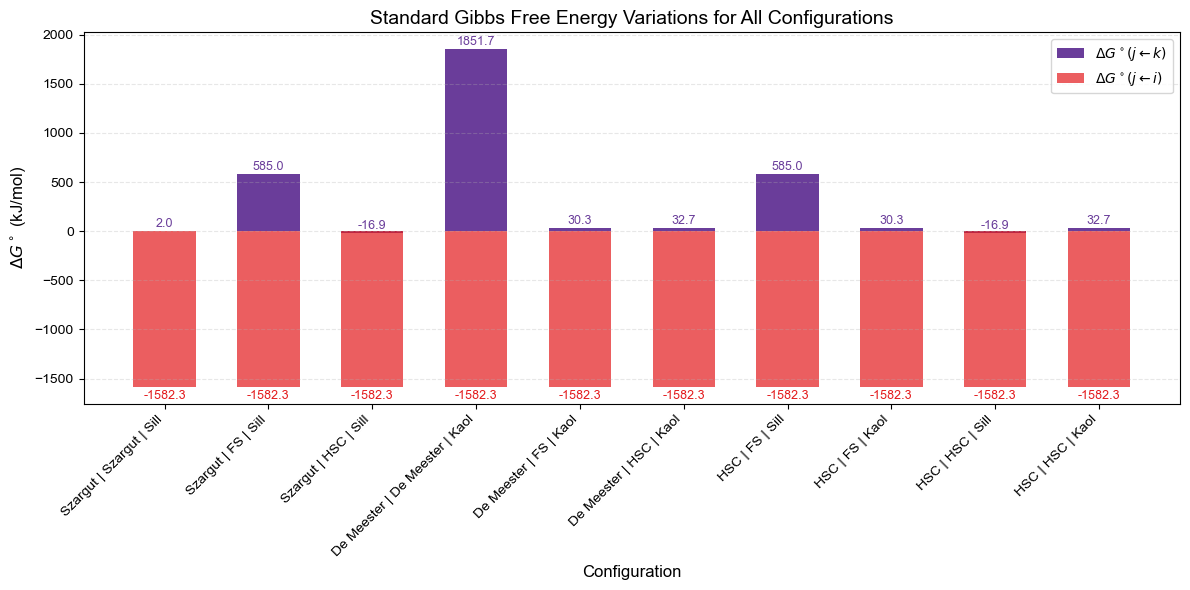

In [31]:
# ============================================================================
# COMPUTE AND DISPLAY ΔG VALUES IN STANDARD STATE
# ============================================================================

# Create a dictionary to store ΔG values for each configuration
delta_G_results = []

for config in configurations:
    try:
        # Compute the results for this configuration
        results = compute_all_G_values(
            DeltafrG_std=config["DeltafrG_std"],
            S_std=S_std_FS if "FactSage" in config["DeltafrG_source"] else (S_std_HSC if "HSC" in config["DeltafrG_source"] else S_std_brgm),
            H_std=H_std,
            G_std=G_std,
            resource=resource,
            reference_elements_i=reference_elements_i,
            reference_species_k=config["env_species_order"],
            reaction_formation_j_from_i=reaction_formation_jfromis_sc,
            reaction_formation_j_from_k=reaction_formation_jfromks_sc_szargut if "Sillimanite" in config["env_species_Al"] else reaction_formation_jfromks_sc_demeester,
            chem_exergy_k=config["chem_exergy_k"],
            chem_exergy_i=config["b_chk_init"],
            Tenv=Tenv,
            standard_state_equivalencies=standard_state_equivalencies
        )

        # Extract the ΔG values in standard state
        delta_G_std_jk = results["DeltaG_std_jk"]  # ΔG°(j ← k)
        delta_G_std_ji = results["DeltaG_std_ji"]  # ΔG°(j ← i)

        # Add to results
        delta_G_results.append({
            "Configuration": config["short_label"],
            "ΔG°(j ← k)": delta_G_std_jk,
            "ΔG°(j ← i)": delta_G_std_ji,
            "ΔG°(k ← i)": results["G_std_sumk_in_j"] - results["G_std_sumi_in_j"]
        })

    except Exception as e:
        print(f"Error computing ΔG for {config['name']}: {e}")
        delta_G_results.append({
            "Configuration": config["short_label"],
            "ΔG°(j ← k)": None,
            "ΔG°(j ← i)": None,
            "ΔG°(k ← i)": None
        })

# Create a DataFrame for the ΔG values
df_delta_G = pd.DataFrame(delta_G_results)

# Display the ΔG values table
print("\n" + "="*100)
print("TABLE: Standard Gibbs Free Energy Variations (ΔG°) for All Configurations")
print("="*100)
print(df_delta_G.to_string(index=False))
print("="*100)

# Plot the ΔG values
plt.figure(figsize=(12, 6))

# Plot ΔG°(j ← k)
bars1 = plt.bar(
    df_delta_G["Configuration"],
    df_delta_G["ΔG°(j ← k)"],
    width=0.6,
    color='#6a3d9a',
    label=r'$\Delta G^\circ(j \leftarrow k)$'
)

# Plot ΔG°(j ← i)
bars2 = plt.bar(
    df_delta_G["Configuration"],
    df_delta_G["ΔG°(j ← i)"],
    width=0.6,
    color='#e31a1c',
    alpha=0.7,
    label=r'$\Delta G^\circ(j \leftarrow i)$'
)

# Add value labels
for bar1, bar2, (jk, ji) in zip(bars1, bars2, zip(df_delta_G["ΔG°(j ← k)"], df_delta_G["ΔG°(j ← i)"])):
    plt.text(bar1.get_x() + bar1.get_width()/2, jk + 10,
             f'{jk:.1f}', ha='center', va='bottom', fontsize=9, color='#6a3d9a')
    plt.text(bar2.get_x() + bar2.get_width()/2, ji - 30,
             f'{ji:.1f}', ha='center', va='top', fontsize=9, color='#e31a1c')

plt.xlabel("Configuration", fontsize=12)
plt.ylabel(r"$\Delta G^\circ$ (kJ/mol)", fontsize=12)
plt.title("Standard Gibbs Free Energy Variations for All Configurations", fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.legend(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('delta_G_standard_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# end and test

In [26]:
import pandas as pd

def compute_B_consistency_table(results_all: dict) -> pd.DataFrame:
    rows = []

    for method, res in results_all.items():

        # --- Form 1: elements route ---
        B_j_1 = res["B_sumi_in_j"] + res["DeltaG_std_ji"]

        # --- Form 2: environmental route ---
        B_j_2 = res["B_sumk_in_j"] + res["DeltaG_std_jk"]

        # --- Form 3: state function route ---
        B_j_3 = res["G_std_j"] - res["G_env_sumk_in_j"]

        # --- Difference ---
        diff = B_j_1 - B_j_2

        rows.append({
            "method": method,
            "B_j_1 (i-route)": B_j_1,
            "B_j_2 (k-route)": B_j_2,
            "B_j_3 (state function route)": B_j_3,
            "difference ik routes": diff,
            "abs_difference ik routes": abs(diff)
        })

    return pd.DataFrame(rows)

In [27]:
df_B_check = compute_B_consistency_table(results_all_complete)
df_B_check

,method,B_j_1 (i-route),B_j_2 (k-route),B_j_3 (state function route),difference ik routes,abs_difference ik routes
0,Szargut | Szargut | Sill,4.3780,4.3830,4.3830,-0.0050,0.0050
1,Szargut | FS | Sill,4.3413,587.3760,587.3760,-583.0347,583.0347
2,Szargut | HSC | Sill,4.3610,-14.5620,-14.5620,18.9230,18.9230
3,De Meester | De Meester | Kaol,1842.2930,1842.2830,1842.2830,0.0100,0.0100
4,De Meester | FS | Kaol,1842.2563,20.8859,20.8859,1821.3704,1821.3704
5,De Meester | HSC | Kaol,1842.2760,23.2270,23.2270,1819.0490,1819.0490
6,HSC | FS | Sill,14.9863,616.9460,616.9460,-601.9597,601.9597
7,HSC | FS | Kaol,14.9863,12.6759,12.6759,2.3104,2.3104
8,HSC | HSC | Sill,15.0060,15.0080,15.0080,-0.0020,0.0020
9,HSC | HSC | Kaol,15.0060,15.0170,15.0170,-0.0110,0.0110


In [14]:
# Interaction plots (2x2) and variance decomposition (percentage contributions)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
import matplotlib as mpl

plt.rcParams['font.family'] = 'Arial'
fontsize_title = 16
fontsize_label = 14
fontsize_ticks = 12
fontsize_legend = 12

# Prepare the data (do not aggregate or average)
df = df_b_chi.copy()
split = df['short_label'].str.split(' | ', n=2, expand=True)
split.columns = ['b_ch_source', 'dG_source', 'ref_env']
df[['b_ch_source', 'dG_source', 'ref_env']] = split
# normalize tokens
df['dG_source'] = df['dG_source'].replace({'FS': 'FactSage', 'Sill': 'Sillimanite'})
df['ref_env'] = df['ref_env'].replace({'Sill': 'Sillimanite', 'Kaol': 'Kaolinite'})

# Long format with one row per element value (explicit values preserved)
df_long = df.melt(id_vars=['short_label','b_ch_source','dG_source','ref_env'], value_vars=['b_O2','b_Si','b_Al','b_H2'], var_name='element', value_name='b_ch')
df_long['element'] = df_long['element'].str.replace('b_','')
# make sure numeric
df_long['b_ch'] = pd.to_numeric(df_long['b_ch'], errors='coerce')

# Set categorical ordering for dG_source if possible
preferred = ['Szargut','FactSage','HSC','De Meester']
present = [p for p in preferred if p in df_long['dG_source'].unique()]
if present:
    df_long['dG_source'] = pd.Categorical(df_long['dG_source'], categories=present, ordered=True)

# Plot settings: colourblind palette, markers for ref_env
sns.set(style='whitegrid')
palette = sns.color_palette('colorblind')
bch_sources = sorted(df_long['b_ch_source'].unique())
colors = {s: palette[i%len(palette)] for i,s in enumerate(bch_sources)}
marker_map = {k: m for k,m in zip(sorted(df_long['ref_env'].unique()), ['o','s','D','^'])}
marker_default='X'

elements = ['O2','Si','Al','H2']
fig, axes = plt.subplots(2,2, figsize=(12,10), constrained_layout=True)
# compute global y-limits to use consistent axis scaling across subplots
ylim_min = df_long['b_ch'].min()
ylim_max = df_long['b_ch'].max()
y_margin = max(1e-6, 0.05*(ylim_max - ylim_min)) if pd.notnull(ylim_min) and pd.notnull(ylim_max) else 1.0
for ax, el in zip(axes.flatten(), elements):
    dfe = df_long[df_long['element']==el].copy()
    if dfe.empty:
        ax.set_visible(False)
        continue
    # plot every configuration explicitly; connect points for same (b_ch_source, ref_env)
    for (src, ref), grp in dfe.groupby(['b_ch_source','ref_env']):
        grp_sorted = grp.sort_values('dG_source')
        x = [list(grp_sorted['dG_source'].cat.categories).index(v) if hasattr(grp_sorted['dG_source'].dtype,'categories') else list(df_long['dG_source'].unique()).index(v) for v in grp_sorted['dG_source']]
        y = grp_sorted['b_ch'].values
        ax.plot(x, y, '-', color=colors.get(src,'k'), lw=1.8, marker=marker_map.get(ref, marker_default), markersize=8, label=f'{src} | {ref}')
        ax.scatter(x, y, c=[colors.get(src,'k')], edgecolor='black', s=70, zorder=3)
    # formatting
    if hasattr(df_long['dG_source'].dtype,'categories'):
        xlabels = list(df_long['dG_source'].cat.categories)
    else:
        xlabels = list(df_long['dG_source'].unique())
    ax.set_xticks(range(len(xlabels)))
    ax.set_xticklabels(xlabels, fontsize=fontsize_ticks)
    ax.set_title(el, fontsize=fontsize_title)
    ax.set_ylabel({'O2':'$b_{ch,O2}^{\circ}$ (kJ/mol)','Si':'$b_{ch,Si}^{\circ}$ (kJ/mol)','Al':'$b_{ch,Al}^{\circ}$ (kJ/mol)','H2':'$b_{ch,H2}^{\circ}$ (kJ/mol)'}[el], fontsize=fontsize_label)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    # consistent y-limits
    ax.set_ylim(ylim_min - y_margin, ylim_max + y_margin)
    ax.tick_params(axis='both', labelsize=fontsize_ticks)
# legends: color -> b_ch_source, marker -> ref_env
color_handles = [mpl.lines.Line2D([0],[0], color=colors[s], lw=3) for s in bch_sources]
color_labels = bch_sources
marker_keys = sorted(df_long['ref_env'].unique())
marker_handles = [mpl.lines.Line2D([0],[0], marker=marker_map.get(mk, marker_default), color='black', linestyle='None', markersize=8) for mk in marker_keys]
# place legends on figure
axes.flatten()[0].legend(color_handles, color_labels, title='b_ch_source', fontsize=10, loc='upper left')
axes.flatten()[1].legend(marker_handles, marker_keys, title='ref_env', fontsize=10, loc='upper right')
plt.suptitle('Interaction plots: b_ch vs ΔG_source (x) — coloured by b_ch_source, markers by ref_env', fontsize=fontsize_title)
plt.savefig('interaction_matrix_bch.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()

# --- Variance decomposition: fit linear model with pairwise interactions and compute % contributions ---
elements_present = sorted(df_long['element'].unique())
var_tables = {}
for el in elements_present:
    dfe = df_long[df_long['element']==el].copy()
    dfe = dfe.dropna(subset=['b_ch'])
    if dfe.shape[0] < 2:
        continue
    # ensure categorical
    dfe['b_ch_source'] = dfe['b_ch_source'].astype('category')
    dfe['dG_source'] = dfe['dG_source'].astype('category')
    dfe['ref_env'] = dfe['ref_env'].astype('category')
    formula = 'b_ch ~ C(b_ch_source) + C(dG_source) + C(ref_env) + C(b_ch_source):C(dG_source) + C(b_ch_source):C(ref_env) + C(dG_source):C(ref_env)'
    model = ols(formula, data=dfe).fit()
    anova = anova_lm(model, typ=2)
    anova = anova.reset_index().rename(columns={'index':'term'})
    total = anova['sum_sq'].sum()
    anova['pct'] = 100.0 * anova['sum_sq'] / total
    var_tables[el] = anova[['term','sum_sq','pct']].set_index('term')
# build consolidated table of % contributions
all_terms = sorted({t for tbl in var_tables.values() for t in tbl.index})
var_df = pd.DataFrame(index=all_terms, columns=elements_present)
for el,tbl in var_tables.items():
    for t in all_terms:
        var_df.loc[t,el] = tbl.loc[t,'pct'] if t in tbl.index else 0.0
var_df = var_df.fillna(0.0).round(2)
print('
Variance decomposition (% contribution to total sum of squares)')
print(var_df.to_string())

# concise interpretation: dominant source per element
print('
Concise interpretation (dominant contributor per element):')
for el in elements_present:
    if el in var_df.columns and not var_df[el].empty:
        top = var_df[el].idxmax()
        pct = var_df.loc[top,el]
        print(f' - {el}: {top} — {pct:.1f}%')


SyntaxError: unterminated string literal (detected at line 114) (2812896071.py, line 114)